# 1. YOLOv12

## 1.1. Training

### 1.1.1. Saudi Vehicle Dataset

In [1]:
!pip install -q ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 37.1 MB/s eta 0:00:00


In [2]:
from ultralytics import YOLO

Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.


In [3]:
import ultralytics
print(ultralytics.__version__)


8.3.237


In [ ]:
model = YOLO("yolo12s.pt")


image 1/1 /content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/train/images/2024_01_23_09_39_18_0_0.png: 640x640 2 laptops, 1 cell phone, 1 oven, 1 refrigerator, 1 clock, 21.2ms
Speed: 13.2ms preprocess, 21.2ms inference, 5.1ms postprocess per image at shape (1, 3, 640, 640)


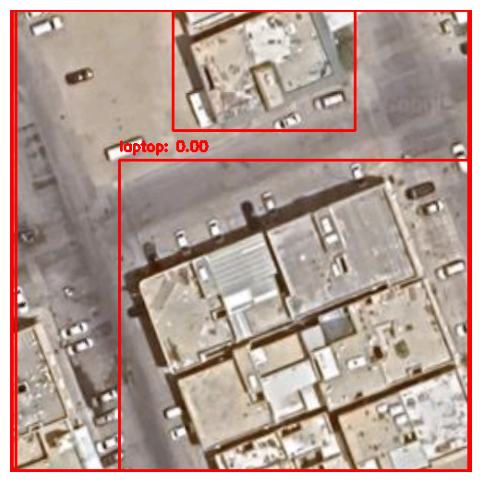

In [ ]:
sample_image_path = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/train/images/2024_01_23_09_39_18_0_0.png"
results = model(sample_image_path, conf=0.0025)  # Set confidence threshold lower (e.g., 0.25)

# Load the original image
import cv2
import matplotlib.pyplot as plt


image = cv2.imread(sample_image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert to RGB for Matplotlib

# Plot results with bounding boxes
for result in results:
    for box in result.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0])  # Get bounding box coordinates
        conf = box.conf[0]  # Confidence score
        class_id = int(box.cls[0])  # Class ID

        # Draw bounding box
        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)
        label = f"{model.names[class_id]}: {conf:.2f}"
        cv2.putText(image, label, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

# Display the image
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
import cv2
import glob

# Get a list of image paths
image_paths = glob.glob("/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/train/images/*.png")

# Ensure the list is not empty
if not image_paths:
    print("No images found in the specified directory.")
else:
    # Read the first image
    image = cv2.imread(image_paths[0])

    if image is None:
        print("Failed to load image. Check the file path.")
    else:
        height, width, _ = image.shape
        print(f"Image size: {width}x{height}")


Image size: 500x500


In [ ]:
results = model.train(data="/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset.yaml", epochs=200, imgsz=500)

Ultralytics 8.3.225 🚀 Python-3.12.12 torch-2.8.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=500, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train2, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience

In [ ]:
# Load the trained model (DO NOT use yolo12n.pt)
model = YOLO("/content/runs/detect/train2/weights/best.pt")

# Run inference on a test image
sample_image_path = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/train/images/2024_01_23_09_39_18_0_0.png"
results = model(sample_image_path, conf=0.25)

# Load the original image
import cv2
import matplotlib.pyplot as plt


image = cv2.imread(sample_image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert to RGB for Matplotlib

# Plot results with bounding boxes
for result in results:
    for box in result.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0])  # Get bounding box coordinates
        conf = box.conf[0]  # Confidence score
        class_id = int(box.cls[0])  # Class ID

        # Draw bounding box
        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)
        label = f"{model.names[class_id]}: {conf:.2f}"
        cv2.putText(image, label, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

# Display the image
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
print(model.names)  # Check the available class IDs

In [ ]:
# import shutil

# # Zip the folder
# shutil.make_archive('/content/runs/detect/train3', 'zip', '/content/runs/detect/train3')

# # Download the ZIP file
# from google.colab import files
# files.download('/content/runs/detect/train3.zip')


In [ ]:
import pandas as pd

# Load training results
df = pd.read_csv("/content/runs/detect/train3/results.csv")

In [ ]:
df.info()

In [ ]:
# Get the last row (final epoch)
final_metrics = df.iloc[-1]

# Display as a table
table = final_metrics
print(table)

In [ ]:
import pandas as pd

# Load training results
df = pd.read_csv("/content/runs/detect/train3/results.csv")

# Get the last row (latest epoch)
precision = df["metrics/precision(B)"].iloc[-1]
recall = df["metrics/recall(B)"].iloc[-1]

# Compute F1-score
f1_score = 2 * (precision * recall) / (precision + recall)
print(f"F1-Score: {f1_score:.4f}")


### 1.1.2. COWC

In [ ]:
sample_image_path = "/content/drive/MyDrive/vehicle_detection/cowc_dataset/test/images/03553_10_png.rf.15ed65f027503fef16a9f1b705190e1d.jpg"
results = model(sample_image_path, conf=0.0025)  # Set confidence threshold lower (e.g., 0.25)

# Load the original image
import cv2
import matplotlib.pyplot as plt


image = cv2.imread(sample_image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert to RGB for Matplotlib

# Plot results with bounding boxes
for result in results:
    for box in result.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0])  # Get bounding box coordinates
        conf = box.conf[0]  # Confidence score
        class_id = int(box.cls[0])  # Class ID

        # Draw bounding box
        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)
        label = f"{model.names[class_id]}: {conf:.2f}"
        cv2.putText(image, label, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

# Display the image
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
import cv2
import glob

# Get a list of image paths
image_paths = glob.glob("/content/drive/MyDrive/vehicle_detection/cowc_dataset/test/images/*.jpg")

# Ensure the list is not empty
if not image_paths:
    print("No images found in the specified directory.")
else:
    # Read the first image
    image = cv2.imread(image_paths[0])

    if image is None:
        print("Failed to load image. Check the file path.")
    else:
        height, width, _ = image.shape
        print(f"Image size: {width}x{height}")


In [ ]:
model = YOLO("/content/drive/MyDrive/vehicle_detection/train_4_cowc/weights/best.pt")

In [ ]:
results = model.train(data="/content/drive/MyDrive/vehicle_detection/cowc_dataset.yaml", epochs=80, imgsz=682)

In [ ]:
# import shutil

# # Zip the folder
# shutil.make_archive('/content/runs/detect/train', 'zip', '/content/runs/detect/train')

# # Download the ZIP file
# from google.colab import files
# files.download('/content/runs/detect/train.zip')


In [ ]:
import pandas as pd

# Load training results
df = pd.read_csv("/content/drive/MyDrive/vehicle_detection/train_4_cowc_2/results.csv")

# Get the last row (latest epoch)
precision = df["metrics/precision(B)"].iloc[-1]
recall = df["metrics/recall(B)"].iloc[-1]
mAP50 = df["metrics/mAP50(B)"].iloc[-1]

# Compute F1-score
f1_score = 2 * (precision * recall) / (precision + recall)
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1-Score: {f1_score:.3f}")
print(f"mAP50: {mAP50:.3f}")

In [ ]:
model = YOLO("/content/drive/MyDrive/vehicle_detection/train_4_cowc_2/weights/best.pt")

In [ ]:
sample_image_path = "/content/drive/MyDrive/vehicle_detection/cowc_dataset/test/images/03553_10_png.rf.15ed65f027503fef16a9f1b705190e1d.jpg"
results = model(sample_image_path, conf=0.0025)  # Set confidence threshold lower (e.g., 0.25)


### 1.1.3. Synthetic Car

In [ ]:
sample_image_path = "/content/drive/MyDrive/vehicle_detection/synthetic_car_dataset/test/images/2852.png"
results = model(sample_image_path, conf=0.0025)  # Set confidence threshold lower (e.g., 0.25)

# Load the original image
import cv2
import matplotlib.pyplot as plt


image = cv2.imread(sample_image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert to RGB for Matplotlib

# Plot results with bounding boxes
for result in results:
    for box in result.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0])  # Get bounding box coordinates
        conf = box.conf[0]  # Confidence score
        class_id = int(box.cls[0])  # Class ID

        # Draw bounding box
        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)
        label = f"{model.names[class_id]}: {conf:.2f}"
        cv2.putText(image, label, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

# Display the image
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
import cv2
import glob

# Get a list of image paths
image_paths = glob.glob("/content/drive/MyDrive/vehicle_detection/synthetic_car_dataset/test/images/*.png")

# Ensure the list is not empty
if not image_paths:
    print("No images found in the specified directory.")
else:
    # Read the first image
    image = cv2.imread(image_paths[0])

    if image is None:
        print("Failed to load image. Check the file path.")
    else:
        height, width, _ = image.shape
        print(f"Image size: {width}x{height}")


Image size: 500x500


In [ ]:
results = model.train(data="/content/drive/MyDrive/vehicle_detection/synthetic_car_dataset.yaml", epochs=200, imgsz=500)

Ultralytics 8.3.92 🚀 Python-3.11.11 torch-2.6.0+cu124 CPU (Intel Xeon 2.20GHz)
engine/trainer: task=detect, mode=train, model=yolo12n.pt, data=/content/drive/MyDrive/vehicle_detection/synthetic_car_dataset.yaml, epochs=200, time=None, patience=100, batch=16, imgsz=500, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, save_frames=False, save_txt=False, save_conf=False, save_crop=False, show_

100%|██████████| 755k/755k [00:00<00:00, 15.6MB/s]


Overriding model.yaml nc=80 with nc=1

                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      6640  ultralytics.nn.modules.block.C3k2            [32, 64, 1, False, 0.25]      
  3                  -1  1     36992  ultralytics.nn.modules.conv.Conv             [64, 64, 3, 2]                
  4                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  5                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  6                  -1  2    180864  ultralytics.nn.modules.block.A2C2f           [128, 128, 2, True, 4]        
  7                  -1  1    295424  ultralytics

train: Scanning /content/drive/MyDrive/vehicle_detection/synthetic_car_dataset/train/labels... 35 images, 4 backgrounds, 0 corrupt: 100%|██████████| 35/35 [00:21<00:00,  1.65it/s]

train: New cache created: /content/drive/MyDrive/vehicle_detection/synthetic_car_dataset/train/labels.cache


albumentations: Blur(p=0.01, blur_limit=(3, 7)), MedianBlur(p=0.01, blur_limit=(3, 7)), ToGray(p=0.01, num_output_channels=3, method='weighted_average'), CLAHE(p=0.01, clip_limit=(1.0, 4.0), tile_grid_size=(8, 8))


... (601 outputs left out)

                   all          5         28          1      0.924      0.943      0.551



200 epochs completed in 1.605 hours.
Optimizer stripped from runs/detect/train/weights/last.pt, 5.5MB
Optimizer stripped from runs/detect/train/weights/best.pt, 5.5MB

Validating runs/detect/train/weights/best.pt...
Ultralytics 8.3.92 🚀 Python-3.11.11 torch-2.6.0+cu124 CPU (Intel Xeon 2.20GHz)
YOLOv12n summary (fused): 159 layers, 2,556,923 parameters, 0 gradients, 6.3 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:01<00:00,  1.64s/it]


                   all          5         28       0.99      0.893      0.928      0.584
Speed: 1.7ms preprocess, 276.5ms inference, 0.0ms loss, 1.6ms postprocess per image
Results saved to runs/detect/train



image 1/1 /content/drive/MyDrive/vehicle_detection/synthetic_car_dataset/test/images/2852.png: 512x512 4 vehicles, 243.2ms
Speed: 5.0ms preprocess, 243.2ms inference, 2.8ms postprocess per image at shape (1, 3, 512, 512)


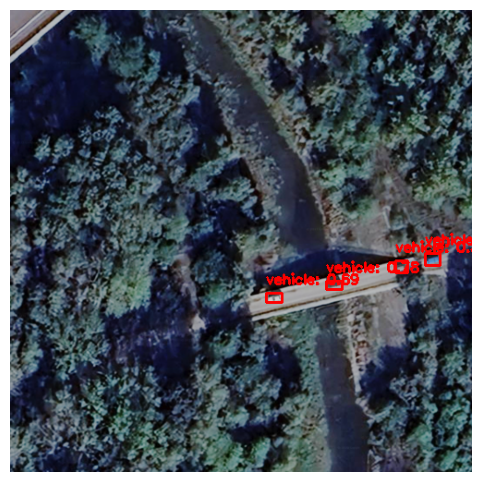

In [ ]:
# Load the trained model (DO NOT use yolo12n.pt)
model = YOLO("/content/runs/detect/train/weights/best.pt")

# Run inference on a test image
sample_image_path = "/content/drive/MyDrive/vehicle_detection/synthetic_car_dataset/test/images/2852.png"
results = model(sample_image_path, conf=0.25)

# Load the original image
import cv2
import matplotlib.pyplot as plt


image = cv2.imread(sample_image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert to RGB for Matplotlib

# Plot results with bounding boxes
for result in results:
    for box in result.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0])  # Get bounding box coordinates
        conf = box.conf[0]  # Confidence score
        class_id = int(box.cls[0])  # Class ID

        # Draw bounding box
        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)
        label = f"{model.names[class_id]}: {conf:.2f}"
        cv2.putText(image, label, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

# Display the image
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
# import shutil

# # Zip the folder
# shutil.make_archive('/content/runs/detect/train', 'zip', '/content/runs/detect/train')

# # Download the ZIP file
# from google.colab import files
# files.download('/content/runs/detect/train.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

# Load training results
df = pd.read_csv("/content/runs/detect/train/results.csv")

# Get the last row (latest epoch)
precision = df["metrics/precision(B)"].iloc[-1]
recall = df["metrics/recall(B)"].iloc[-1]
mAP50 = df["metrics/mAP50(B)"].iloc[-1]

# Compute F1-score
f1_score = 2 * (precision * recall) / (precision + recall)
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1-Score: {f1_score:.3f}")
print(f"mAP50: {mAP50:.3f}")

Precision: 1.000
Recall: 0.924
F1-Score: 0.961
mAP50: 0.943


### 1.1.4. Car Swimming Pol

In [ ]:
model = YOLO("/content/drive/MyDrive/vehicle_detection/train_car_swimmping_pool_run/weights/best.pt")


image 1/1 /content/drive/MyDrive/vehicle_detection/car_swimming_pool_dataset/test/images/000000653.jpg: 224x224 15 vehicles, 26.3ms
Speed: 1.3ms preprocess, 26.3ms inference, 1.8ms postprocess per image at shape (1, 3, 224, 224)


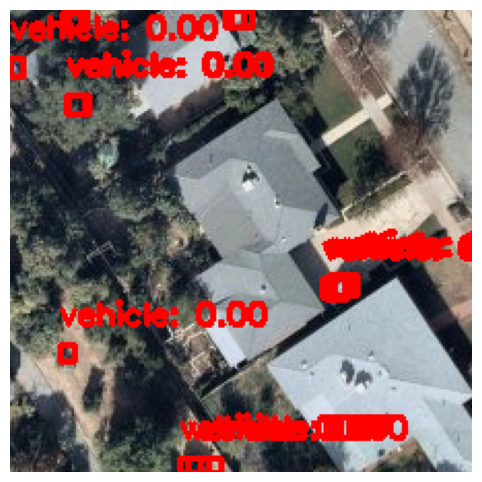

In [ ]:
sample_image_path = "/content/drive/MyDrive/vehicle_detection/car_swimming_pool_dataset/test/images/000000653.jpg"
results = model(sample_image_path, conf=0.0025)  # Set confidence threshold lower (e.g., 0.25)

# Load the original image
import cv2
import matplotlib.pyplot as plt


image = cv2.imread(sample_image_path)
image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)  # Convert to RGB for Matplotlib

# Plot results with bounding boxes
for result in results:
    for box in result.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0])  # Get bounding box coordinates
        conf = box.conf[0]  # Confidence score
        class_id = int(box.cls[0])  # Class ID

        # Draw bounding box
        cv2.rectangle(image, (x1, y1), (x2, y2), (255, 0, 0), 2)
        label = f"{model.names[class_id]}: {conf:.2f}"
        cv2.putText(image, label, (x1, y1 - 10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (255, 0, 0), 2)

# Display the image
plt.figure(figsize=(8, 6))
plt.imshow(image)
plt.axis("off")
plt.show()

In [ ]:
import cv2
import glob

# Get a list of image paths
image_paths = glob.glob("/content/drive/MyDrive/vehicle_detection/car_swimming_pool_dataset/test/images/*.jpg")

# Ensure the list is not empty
if not image_paths:
    print("No images found in the specified directory.")
else:
    # Read the first image
    image = cv2.imread(image_paths[0])

    if image is None:
        print("Failed to load image. Check the file path.")
    else:
        height, width, _ = image.shape
        print(f"Image size: {width}x{height}")


Image size: 224x224


In [ ]:
200-121

79

In [ ]:
results = model.train(data="/content/drive/MyDrive/vehicle_detection/car_swimming_pool.yaml", epochs=79, imgsz=224)

Ultralytics 8.3.97 🚀 Python-3.11.11 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: task=detect, mode=train, model=/content/drive/MyDrive/vehicle_detection/train_car_swimmping_pool_run/weights/best.pt, data=/content/drive/MyDrive/vehicle_detection/car_swimming_pool.yaml, epochs=79, time=None, patience=100, batch=16, imgsz=224, save=True, save_period=-1, cache=False, device=None, workers=8, project=None, name=train, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False, embed=None, show=False, s

100%|██████████| 755k/755k [00:00<00:00, 41.0MB/s]



                   from  n    params  module                                       arguments                     
  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 
  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                
  2                  -1  1      6640  ultralytics.nn.modules.block.C3k2            [32, 64, 1, False, 0.25]      
  3                  -1  1     36992  ultralytics.nn.modules.conv.Conv             [64, 64, 3, 2]                
  4                  -1  1     26080  ultralytics.nn.modules.block.C3k2            [64, 128, 1, False, 0.25]     
  5                  -1  1    147712  ultralytics.nn.modules.conv.Conv             [128, 128, 3, 2]              
  6                  -1  2    180864  ultralytics.nn.modules.block.A2C2f           [128, 128, 2, True, 4]        
  7                  -1  1    295424  ultralytics.nn.modules.conv.Conv             [128

100%|██████████| 5.35M/5.35M [00:00<00:00, 174MB/s]


AMP: checks passed ✅


train: Scanning /content/drive/MyDrive/vehicle_detection/car_swimming_pool_dataset/train/labels.cache... 740 images, 0 backgrounds, 34 corrupt: 100%|██████████| 740/740 [00:00<?, ?it/s]

... (238 outputs left out)

                   all        104        203      0.779        0.7      0.748      0.306



79 epochs completed in 0.331 hours.
Optimizer stripped from runs/detect/train/weights/last.pt, 5.5MB
Optimizer stripped from runs/detect/train/weights/best.pt, 5.5MB

Validating runs/detect/train/weights/best.pt...
Ultralytics 8.3.97 🚀 Python-3.11.11 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv12n summary (fused): 159 layers, 2,556,923 parameters, 0 gradients, 6.3 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 4/4 [00:01<00:00,  2.74it/s]


                   all        104        203       0.81        0.7      0.749      0.308
Speed: 0.3ms preprocess, 3.8ms inference, 0.0ms loss, 3.1ms postprocess per image
Results saved to runs/detect/train


In [ ]:
# import shutil

# # Zip the folder
# shutil.make_archive('/content/runs/detect/train', 'zip', '/content/runs/detect/train')

# # Download the ZIP file
# from google.colab import files
# files.download('/content/runs/detect/train.zip')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

# Load training results
df = pd.read_csv("/content/runs/detect/train/results.csv")

# Get the last row (latest epoch)
precision = df["metrics/precision(B)"].iloc[-1]
recall = df["metrics/recall(B)"].iloc[-1]
mAP50 = df["metrics/mAP50(B)"].iloc[-1]

# Compute F1-score
f1_score = 2 * (precision * recall) / (precision + recall)
print(f"Precision: {precision:.3f}")
print(f"Recall: {recall:.3f}")
print(f"F1-Score: {f1_score:.3f}")
print(f"mAP50: {mAP50:.3f}")

Precision: 0.779
Recall: 0.700
F1-Score: 0.737
mAP50: 0.748


In [ ]:
df

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,185.892,1.97310,1.29130,0.86361,0.70395,0.57143,0.59606,0.20000,2.57680,1.29904,0.89356,0.000652,0.000652,0.000652
1,2,199.149,1.97812,1.25848,0.85577,0.81639,0.63517,0.67133,0.21926,2.38940,1.26132,0.88159,0.001302,0.001302,0.001302
2,3,211.956,2.06959,1.23090,0.86311,0.71827,0.56158,0.57957,0.17895,2.58193,1.44093,0.89832,0.001935,0.001935,0.001935
3,4,224.536,2.15881,1.29203,0.87287,0.76293,0.55486,0.57822,0.16168,2.72963,1.31497,0.91953,0.001925,0.001925,0.001925
4,5,236.387,2.14306,1.29025,0.86853,0.53502,0.47612,0.43463,0.08159,3.28456,1.53931,0.97032,0.001900,0.001900,0.001900
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
74,75,1139.500,1.54522,0.86446,0.83718,0.80967,0.66995,0.73209,0.28617,2.31784,1.19161,0.86838,0.000145,0.000145,0.000145
75,76,1152.080,1.56337,0.89844,0.83917,0.81455,0.69238,0.73896,0.27999,2.37112,1.19952,0.87228,0.000120,0.000120,0.000120
76,77,1164.770,1.59885,0.90830,0.83761,0.80875,0.68742,0.73473,0.28253,2.36924,1.20200,0.87260,0.000095,0.000095,0.000095
77,78,1177.380,1.49993,0.87527,0.82781,0.81543,0.69458,0.74910,0.30925,2.22355,1.17397,0.86160,0.000070,0.000070,0.000070


## 1.2. Testing

### 1.2.1. Saudi Vehicle Dataset

In [ ]:
from ultralytics import YOLO

# Load the trained model
model = YOLO("/content/drive/MyDrive/vehicle_detection/train_saudi_vehicle_run/weights/best.pt")

# Run validation on test data
results = model.val(data="/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset.yaml", split="test", imgsz=500)


WARNING ⚠️ imgsz=[500] must be multiple of max stride 32, updating to [512]
Ultralytics 8.3.97 🚀 Python-3.11.11 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv12n summary (fused): 159 layers, 2,556,923 parameters, 0 gradients, 6.3 GFLOPs


val: Scanning /content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/test/labels... 112 images, 3 backgrounds, 0 corrupt: 100%|██████████| 112/112 [01:01<00:00,  1.83it/s]

val: New cache created: /content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/test/labels.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 7/7 [00:05<00:00,  1.18it/s]


                   all        112       1097      0.929      0.906      0.962      0.578
Speed: 4.9ms preprocess, 9.0ms inference, 0.0ms loss, 4.2ms postprocess per image
Results saved to runs/detect/val4


In [ ]:
recall = 1016/(1016+81)
precision = 1016/(1016+119)
f1 = (2*recall*precision)/(recall+precision)
print(recall, precision, f1)

0.92616226071103 0.8951541850220265 0.910394265232975


### 1.2.2. COWC

In [ ]:
from ultralytics import YOLO

# Load the trained model
model = YOLO("/content/drive/MyDrive/vehicle_detection/train_cowc_run_2/weights/best.pt")

# Run validation on test data
results = model.val(data="/content/drive/MyDrive/vehicle_detection/cowc_dataset.yaml", split="test", imgsz=682)


WARNING ⚠️ imgsz=[682] must be multiple of max stride 32, updating to [704]
Ultralytics 8.3.97 🚀 Python-3.11.11 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv12n summary (fused): 159 layers, 2,556,923 parameters, 0 gradients, 6.3 GFLOPs


val: Scanning /content/drive/MyDrive/vehicle_detection/cowc_dataset/test/labels... 262 images, 112 backgrounds, 0 corrupt: 100%|██████████| 267/267 [01:27<00:00,  3.05it/s]


val: New cache created: /content/drive/MyDrive/vehicle_detection/cowc_dataset/test/labels.cache


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 17/17 [00:10<00:00,  1.67it/s]


                   all        267       6474       0.92      0.841      0.905      0.595
Speed: 4.3ms preprocess, 9.9ms inference, 0.0ms loss, 2.3ms postprocess per image
Results saved to runs/detect/val5


In [ ]:
recall = 5699/(5699+775)
precision = 5699/(5699+964)
f1 = (2*recall*precision)/(recall+precision)
print(recall, precision, f1)

0.8802903923385851 0.8553204262344289 0.8676257897541295


### 1.2.3. Synthetic Car

In [ ]:
from ultralytics import YOLO

# Load the trained model
model = YOLO("/content/drive/MyDrive/vehicle_detection/train_synthetic_car_run/weights/best.pt")

# Run validation on test data
results = model.val(data="/content/drive/MyDrive/vehicle_detection/synthetic_car_dataset.yaml", split="test", imgsz=500)


WARNING ⚠️ imgsz=[500] must be multiple of max stride 32, updating to [512]
Ultralytics 8.3.97 🚀 Python-3.11.11 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv12n summary (fused): 159 layers, 2,556,923 parameters, 0 gradients, 6.3 GFLOPs


val: Scanning /content/drive/MyDrive/vehicle_detection/synthetic_car_dataset/test/labels... 10 images, 0 backgrounds, 0 corrupt: 100%|██████████| 10/10 [00:11<00:00,  1.12s/it]

val: New cache created: /content/drive/MyDrive/vehicle_detection/synthetic_car_dataset/test/labels.cache



                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 1/1 [00:00<00:00,  1.61it/s]


                   all         10         59      0.913       0.78      0.872      0.473
Speed: 0.2ms preprocess, 10.2ms inference, 0.0ms loss, 1.2ms postprocess per image
Results saved to runs/detect/val7


In [ ]:
recall = 46/(46+13)
precision = 46/(46+5)
f1 = (2*recall*precision)/(recall+precision)
print(recall, precision, f1)

0.7796610169491526 0.9019607843137255 0.8363636363636364


### 1.2.4. Car Swimming Pool

In [ ]:
from ultralytics import YOLO

# Load the trained model
model = YOLO("/content/runs/detect/train/weights/best.pt")

# Run validation on test data
results = model.val(data="/content/drive/MyDrive/vehicle_detection/car_swimming_pool.yaml", split="test", imgsz=224)


Ultralytics 8.3.97 🚀 Python-3.11.11 torch-2.6.0+cu124 CUDA:0 (Tesla T4, 15095MiB)
YOLOv12n summary (fused): 159 layers, 2,556,923 parameters, 0 gradients, 6.3 GFLOPs


val: Scanning /content/drive/MyDrive/vehicle_detection/car_swimming_pool_dataset/test/labels... 212 images, 0 backgrounds, 10 corrupt: 100%|██████████| 212/212 [01:54<00:00,  1.85it/s]

val: WARNING ⚠️ /content/drive/MyDrive/vehicle_detection/car_swimming_pool_dataset/test/images/000000656.jpg: ignoring corrupt image/label: negative label values [ -0.0015179]
val: WARNING ⚠️ /content/drive/MyDrive/vehicle_detection/car_swimming_pool_dataset/test/images/000000658.jpg: ignoring corrupt image/label: negative label values [ -0.0015179]
val: WARNING ⚠️ /content/drive/MyDrive/vehicle_detection/car_swimming_pool_dataset/test/images/000000902.jpg: ignoring corrupt image/label: negative label values [ -0.0015179]
val: WARNING ⚠️ /content/drive/MyDrive/vehicle_detection/car_swimming_pool_dataset/test/images/000003224.jpg: ignoring corrupt image/label: negative label values [  -0.003683]
val: WARNING ⚠️ /content/drive/MyDrive/vehicle_detection/car_swimming_pool_dataset/test/images/000003225.jpg: ignoring corrupt image/label: negative label values [  -0.003683]
val: WARNING ⚠️ /content/drive/MyDrive/vehicle_detection/car_swimming_pool_dataset/test/images/000003349.jpg: ignoring c


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 13/13 [00:02<00:00,  4.41it/s]


                   all        202        544       0.82      0.627      0.689      0.237
Speed: 0.6ms preprocess, 4.5ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to runs/detect/val


In [ ]:
recall = 380/(380+164)
precision = 380/(380+116)
f1 = (2*recall*precision)/(recall+precision)
print(recall, precision, f1)

0.6985294117647058 0.7661290322580645 0.7307692307692308


## 1.3.Plot

In [ ]:
import pandas as pd
saudi_eval = pd.read_csv("/content/drive/MyDrive/vehicle_detection/train_saudi_vehicle_run/results.csv")
saudi_eval

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,20.2178,3.25723,3.58724,2.64573,0.00005,0.00086,0.00002,0.00000,5.57764,3.80942,3.30558,0.000380,0.000380,0.000380
1,2,33.8394,2.50125,2.48228,1.83577,0.02249,0.41187,0.02481,0.00747,3.18020,3.31161,1.92863,0.000776,0.000776,0.000776
2,3,47.1497,2.09618,1.50873,1.43894,0.66693,0.61637,0.64889,0.26760,2.08638,1.94327,1.37108,0.001168,0.001168,0.001168
3,4,59.4023,1.94838,1.27423,1.30771,0.69086,0.68983,0.72304,0.31290,1.95887,1.39856,1.34661,0.001557,0.001557,0.001557
4,5,71.7659,1.83310,1.19252,1.24825,0.78221,0.76870,0.83779,0.40666,1.74559,1.21499,1.27433,0.001941,0.001941,0.001941
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
195,196,2336.2300,1.06766,0.49309,0.95527,0.94481,0.93723,0.97427,0.58653,1.40577,0.55250,1.09880,0.000069,0.000069,0.000069
196,197,2348.4700,1.08653,0.50566,0.95953,0.94686,0.93458,0.97436,0.58567,1.40944,0.55381,1.10132,0.000060,0.000060,0.000060
197,198,2361.6900,1.07113,0.49948,0.95517,0.94409,0.93981,0.97664,0.58690,1.40887,0.55248,1.10090,0.000050,0.000050,0.000050
198,199,2374.0800,1.06870,0.49831,0.94492,0.94462,0.93871,0.97657,0.58767,1.40829,0.55178,1.10052,0.000040,0.000040,0.000040


In [ ]:
cowc_1_eval = pd.read_csv("/content/drive/MyDrive/vehicle_detection/train_cowc_run/results.csv")
cowc_2_eval = pd.read_csv("/content/drive/MyDrive/vehicle_detection/train_cowc_run_2/results.csv")
synthetic_eval = pd.read_csv("/content/drive/MyDrive/vehicle_detection/train_synthetic_car_run/results.csv")

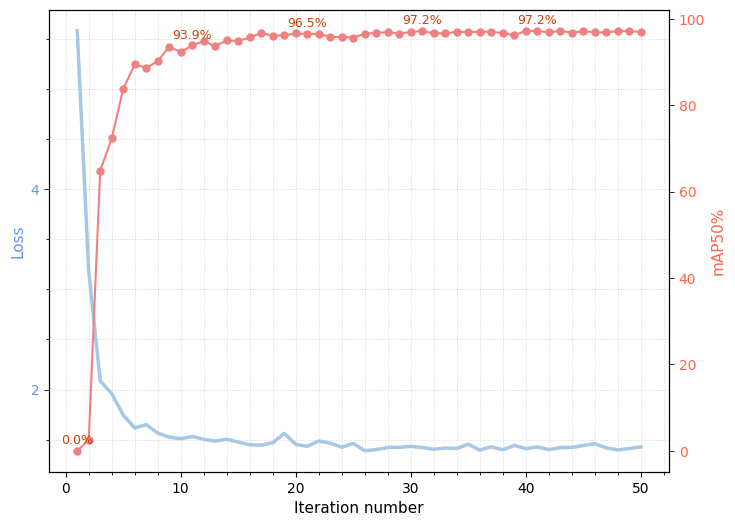

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Load CSV file
saudi_eval = pd.read_csv("/content/drive/MyDrive/vehicle_detection/train_saudi_vehicle_run/results.csv")

# Extract relevant data (Only first 50 iterations)
saudi_eval = saudi_eval[saudi_eval["epoch"] <= 50]

# Extract relevant columns
iterations = saudi_eval["epoch"]
loss = saudi_eval["val/box_loss"]  # Validation loss
map50 = saudi_eval["metrics/mAP50(B)"] * 100  # Convert to percentage

# Create plot
fig, ax1 = plt.subplots(figsize=(8, 6))

# Plot loss curve (Pastel Blue)
ax1.plot(iterations, loss, color="#A7C7E7", linewidth=2.5, label="Loss")  # Soft pastel blue
ax1.set_xlabel("Iteration number", fontsize=11)
ax1.set_ylabel("Loss", color="#6495ED", fontsize=11)  # Cornflower Blue
ax1.tick_params(axis="y", labelcolor="#6495ED", width=0.6)

# Secondary y-axis for mAP% (Pastel Red)
ax2 = ax1.twinx()
ax2.plot(iterations, map50, color="#F08080", marker="o", markersize=5, linewidth=1.5, label="mAP50%")  # Light Coral
ax2.set_ylabel("mAP50%", color="#FF6347", fontsize=11)  # Tomato Red
ax2.tick_params(axis="y", labelcolor="#FF6347", width=0.6)

# Annotate mAP values every 10 steps
for i in range(0, len(iterations), 10):
    ax2.annotate(f"{map50.iloc[i]:.1f}%",
                 (iterations.iloc[i], map50.iloc[i]),
                 textcoords="offset points", xytext=(0, 5), ha="center",
                 fontsize=9, color="#D43F00")  # Darker Tomato Red

# Enable fine grid with better contrast
ax1.xaxis.set_major_locator(ticker.MultipleLocator(10))  # Major grid every 10
ax1.xaxis.set_minor_locator(ticker.MultipleLocator(2))   # Minor grid every 2
ax1.yaxis.set_major_locator(ticker.MultipleLocator(2))   # Major grid every 2
ax1.yaxis.set_minor_locator(ticker.MultipleLocator(0.5)) # Minor grid every 0.5

ax1.grid(which="both", linestyle="--", linewidth=0.4, color="#B0B0B0", alpha=0.5)  # Light gray grid, more visible

# # Title
# plt.title("Loss and mAP50% Over First 50 Iterations", fontsize=12)

# Show plot
plt.show()


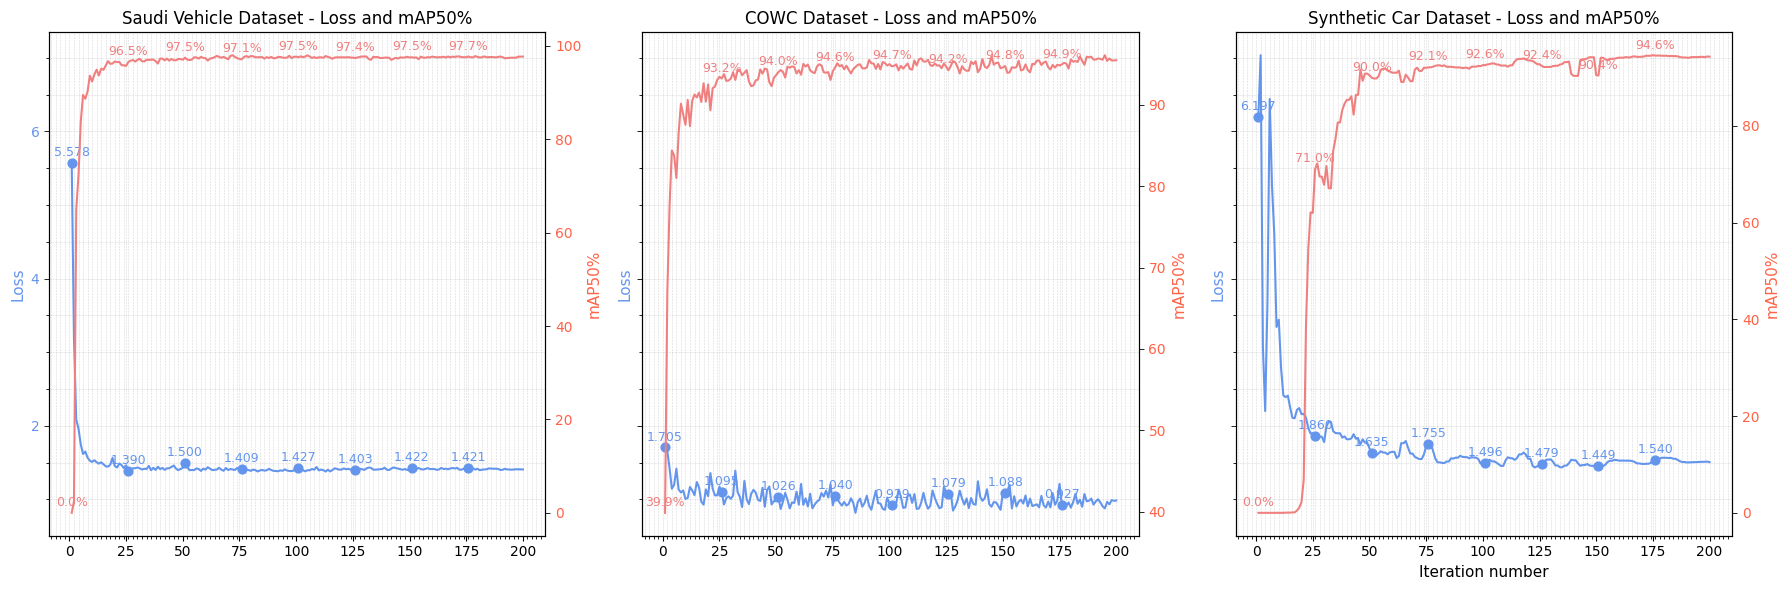

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Load CSV files
saudi_eval = pd.read_csv("/content/drive/MyDrive/vehicle_detection/train_saudi_vehicle_run/results.csv")
cowc_1_eval = pd.read_csv("/content/drive/MyDrive/vehicle_detection/train_cowc_run/results.csv")
cowc_2_eval = pd.read_csv("/content/drive/MyDrive/vehicle_detection/train_cowc_run_2/results.csv")
synthetic_eval = pd.read_csv("/content/drive/MyDrive/vehicle_detection/train_synthetic_car_run/results.csv")

# Extract relevant data (Only first 200 iterations for all evals)
saudi_eval = saudi_eval[saudi_eval["epoch"] <= 200]
iterations_saudi = saudi_eval["epoch"]
loss_saudi = saudi_eval["val/box_loss"]
map50_saudi = saudi_eval["metrics/mAP50(B)"] * 100

# Adjust epoch values for cowc_2_eval to start from the last epoch of cowc_1_eval + 1
last_epoch_cowc_1 = cowc_1_eval["epoch"].max()
cowc_2_eval["epoch"] = cowc_2_eval["epoch"] + last_epoch_cowc_1

# Concatenate cowc_1_eval and cowc_2_eval into one DataFrame for cowc_eval
cowc_eval = pd.concat([cowc_1_eval, cowc_2_eval], ignore_index=True)

# Extract relevant data (Only first 200 iterations for cowc_eval)
cowc_eval = cowc_eval[cowc_eval["epoch"] <= 200]
iterations_cowc = cowc_eval["epoch"]
loss_cowc = cowc_eval["val/box_loss"]
map50_cowc = cowc_eval["metrics/mAP50(B)"] * 100

# For synthetic_eval
synthetic_eval = synthetic_eval[synthetic_eval["epoch"] <= 200]
iterations_synthetic = synthetic_eval["epoch"]
loss_synthetic = synthetic_eval["val/box_loss"]
map50_synthetic = synthetic_eval["metrics/mAP50(B)"] * 100

# Create subplots (1 row, 3 columns)
fig, axs = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

# First plot (saudi_eval)
loss_color = "#6495ED"  # Color for loss
map50_color = "#F08080"  # Color for mAP50%

axs[0].plot(iterations_saudi, loss_saudi, color=loss_color, linewidth=1.5, label="Loss")
axs[0].set_ylabel("Loss", color=loss_color, fontsize=11)
axs[0].tick_params(axis="y", labelcolor=loss_color, width=0.6)
ax2_0 = axs[0].twinx()
ax2_0.plot(iterations_saudi, map50_saudi, color=map50_color, linewidth=1.5, label="mAP50%")
ax2_0.set_ylabel("mAP50%", color="#FF6347", fontsize=11)
ax2_0.tick_params(axis="y", labelcolor="#FF6347", width=0.6)

# Annotate loss values every 25 iterations for saudi_eval
for i in range(0, len(iterations_saudi), 25):
    axs[0].scatter(iterations_saudi.iloc[i], loss_saudi.iloc[i], color=loss_color, s=40, zorder=5)  # Marker for Loss
    axs[0].annotate(f"{loss_saudi.iloc[i]:.3f}",
                    (iterations_saudi.iloc[i], loss_saudi.iloc[i]),
                    textcoords="offset points", xytext=(0, 5), ha="center",
                    fontsize=9, color=loss_color)

# Annotate mAP values every 25 iterations for saudi_eval
for i in range(0, len(iterations_saudi), 25):
    ax2_0.annotate(f"{map50_saudi.iloc[i]:.1f}%",
                   (iterations_saudi.iloc[i], map50_saudi.iloc[i]),
                   textcoords="offset points", xytext=(0, 5), ha="center",
                   fontsize=9, color=map50_color)

axs[0].set_title("Saudi Vehicle Dataset - Loss and mAP50%", fontsize=12)

# Second plot (cowc_eval)
axs[1].plot(iterations_cowc, loss_cowc, color=loss_color, linewidth=1.5, label="Loss")
axs[1].set_ylabel("Loss", color=loss_color, fontsize=11)
axs[1].tick_params(axis="y", labelcolor=loss_color, width=0.6)
ax2_1 = axs[1].twinx()
ax2_1.plot(iterations_cowc, map50_cowc, color=map50_color, linewidth=1.5, label="mAP50%")
ax2_1.set_ylabel("mAP50%", color="#FF6347", fontsize=11)
ax2_1.tick_params(axis="y", labelcolor="#FF6347", width=0.6)

# Annotate loss values every 25 iterations for cowc_eval
for i in range(0, len(iterations_cowc), 25):
    axs[1].scatter(iterations_cowc.iloc[i], loss_cowc.iloc[i], color=loss_color, s=40, zorder=5)  # Marker for Loss
    axs[1].annotate(f"{loss_cowc.iloc[i]:.3f}",
                    (iterations_cowc.iloc[i], loss_cowc.iloc[i]),
                    textcoords="offset points", xytext=(0, 5), ha="center",
                    fontsize=9, color=loss_color)

# Annotate mAP values every 25 iterations for cowc_eval
for i in range(0, len(iterations_cowc), 25):
    ax2_1.annotate(f"{map50_cowc.iloc[i]:.1f}%",
                   (iterations_cowc.iloc[i], map50_cowc.iloc[i]),
                   textcoords="offset points", xytext=(0, 5), ha="center",
                   fontsize=9, color=map50_color)

axs[1].set_title("COWC Dataset - Loss and mAP50%", fontsize=12)

# Third plot (synthetic_eval)
axs[2].plot(iterations_synthetic, loss_synthetic, color=loss_color, linewidth=1.5, label="Loss")
axs[2].set_ylabel("Loss", color=loss_color, fontsize=11)
axs[2].tick_params(axis="y", labelcolor=loss_color, width=0.6)
ax2_2 = axs[2].twinx()
ax2_2.plot(iterations_synthetic, map50_synthetic, color=map50_color, linewidth=1.5, label="mAP50%")
ax2_2.set_ylabel("mAP50%", color="#FF6347", fontsize=11)
ax2_2.tick_params(axis="y", labelcolor="#FF6347", width=0.6)

# Annotate loss values every 25 iterations for synthetic_eval
for i in range(0, len(iterations_synthetic), 25):
    axs[2].scatter(iterations_synthetic.iloc[i], loss_synthetic.iloc[i], color=loss_color, s=40, zorder=5)  # Marker for Loss
    axs[2].annotate(f"{loss_synthetic.iloc[i]:.3f}",
                    (iterations_synthetic.iloc[i], loss_synthetic.iloc[i]),
                    textcoords="offset points", xytext=(0, 5), ha="center",
                    fontsize=9, color=loss_color)

# Annotate mAP values every 25 iterations for synthetic_eval
for i in range(0, len(iterations_synthetic), 25):
    ax2_2.annotate(f"{map50_synthetic.iloc[i]:.1f}%",
                   (iterations_synthetic.iloc[i], map50_synthetic.iloc[i]),
                   textcoords="offset points", xytext=(0, 5), ha="center",
                   fontsize=9, color=map50_color)

axs[2].set_title("Synthetic Car Dataset - Loss and mAP50%", fontsize=12)

# Fine grid and labeling
for ax in axs:
    ax.xaxis.set_major_locator(ticker.MultipleLocator(25))
    ax.xaxis.set_minor_locator(ticker.MultipleLocator(2))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(2))
    ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.5))
    ax.grid(which="both", linestyle="--", linewidth=0.4, color="#B0B0B0", alpha=0.5)

axs[2].set_xlabel("Iteration number", fontsize=11)
plt.tight_layout()

# Show plot
plt.show()


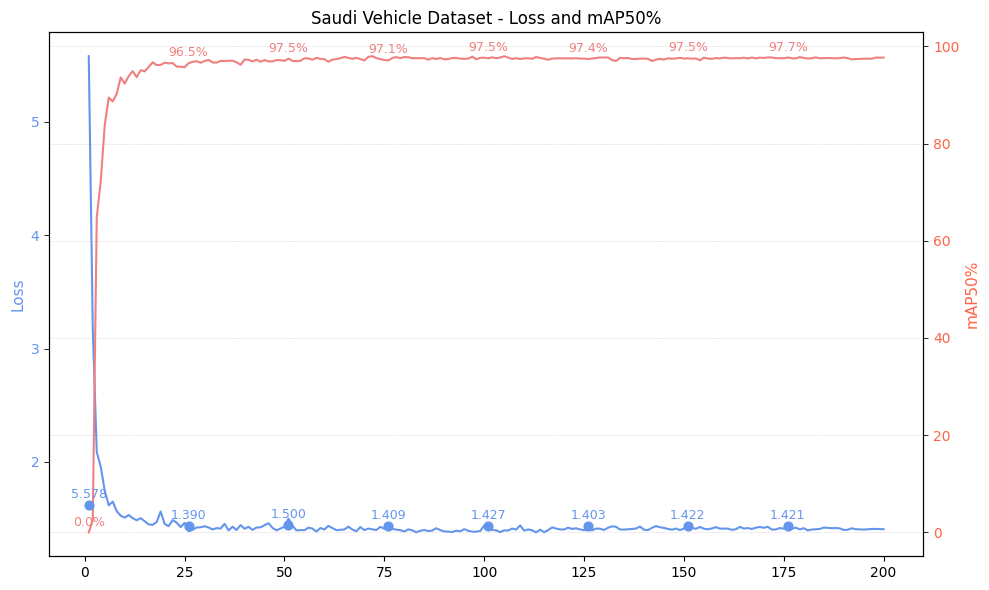

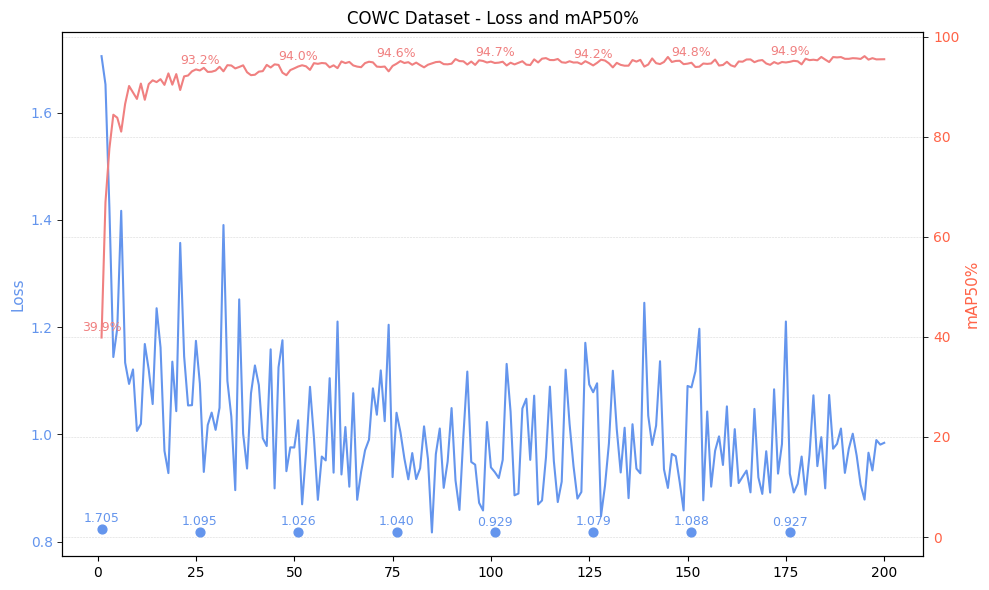

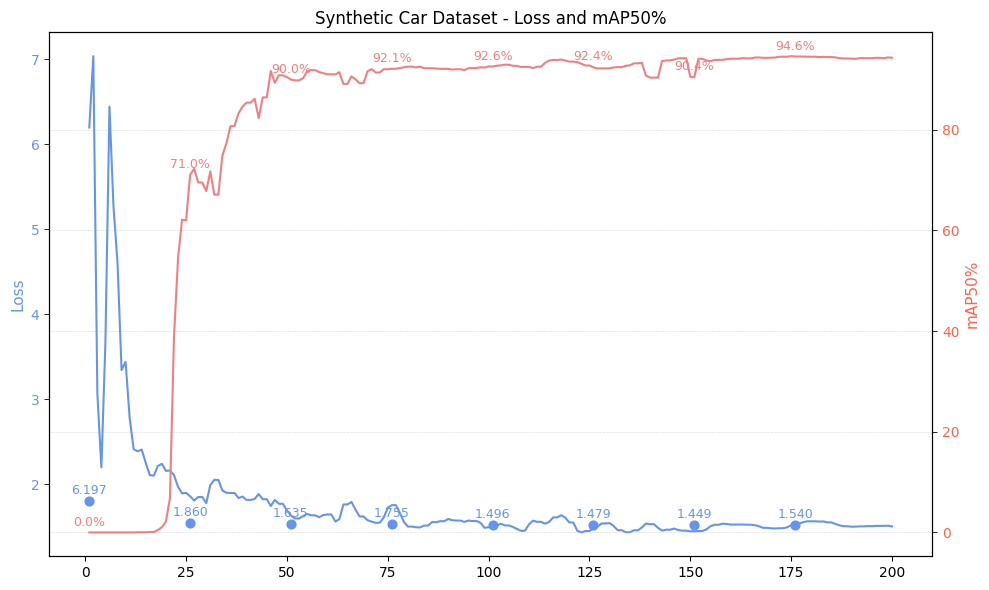

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Load CSV files
saudi_eval = pd.read_csv("/content/drive/MyDrive/vehicle_detection/train_saudi_vehicle_run/results.csv")
cowc_1_eval = pd.read_csv("/content/drive/MyDrive/vehicle_detection/train_cowc_run/results.csv")
cowc_2_eval = pd.read_csv("/content/drive/MyDrive/vehicle_detection/train_cowc_run_2/results.csv")
synthetic_eval = pd.read_csv("/content/drive/MyDrive/vehicle_detection/train_synthetic_car_run/results.csv")

# Extract relevant data (Only first 200 iterations for all evals)
saudi_eval = saudi_eval[saudi_eval["epoch"] <= 200]
iterations_saudi = saudi_eval["epoch"]
loss_saudi = saudi_eval["val/box_loss"]
map50_saudi = saudi_eval["metrics/mAP50(B)"] * 100

# Adjust epoch values for cowc_2_eval to start from the last epoch of cowc_1_eval + 1
last_epoch_cowc_1 = cowc_1_eval["epoch"].max()
cowc_2_eval["epoch"] = cowc_2_eval["epoch"] + last_epoch_cowc_1

# Concatenate cowc_1_eval and cowc_2_eval into one DataFrame for cowc_eval
cowc_eval = pd.concat([cowc_1_eval, cowc_2_eval], ignore_index=True)

# Extract relevant data (Only first 200 iterations for cowc_eval)
cowc_eval = cowc_eval[cowc_eval["epoch"] <= 200]
iterations_cowc = cowc_eval["epoch"]
loss_cowc = cowc_eval["val/box_loss"]
map50_cowc = cowc_eval["metrics/mAP50(B)"] * 100

# For synthetic_eval
synthetic_eval = synthetic_eval[synthetic_eval["epoch"] <= 200]
iterations_synthetic = synthetic_eval["epoch"]
loss_synthetic = synthetic_eval["val/box_loss"]
map50_synthetic = synthetic_eval["metrics/mAP50(B)"] * 100

# Plot for Saudi Vehicle Dataset
plt.figure(figsize=(10, 6))
loss_color = "#6495ED"  # Color for loss
map50_color = "#F08080"  # Color for mAP50%

plt.plot(iterations_saudi, loss_saudi, color=loss_color, linewidth=1.5, label="Loss")
plt.ylabel("Loss", color=loss_color, fontsize=11)
plt.tick_params(axis="y", labelcolor=loss_color, width=0.6)
ax2 = plt.gca().twinx()
ax2.plot(iterations_saudi, map50_saudi, color=map50_color, linewidth=1.5, label="mAP50%")
ax2.set_ylabel("mAP50%", color="#FF6347", fontsize=11)
ax2.tick_params(axis="y", labelcolor="#FF6347", width=0.6)

# Annotate loss and mAP50 values every 25 iterations for Saudi dataset
for i in range(0, len(iterations_saudi), 25):
    plt.scatter(iterations_saudi.iloc[i], loss_saudi.iloc[i], color=loss_color, s=40, zorder=5)
    plt.annotate(f"{loss_saudi.iloc[i]:.3f}", (iterations_saudi.iloc[i], loss_saudi.iloc[i]),
                 textcoords="offset points", xytext=(0, 5), ha="center", fontsize=9, color=loss_color)
    ax2.annotate(f"{map50_saudi.iloc[i]:.1f}%", (iterations_saudi.iloc[i], map50_saudi.iloc[i]),
                 textcoords="offset points", xytext=(0, 5), ha="center", fontsize=9, color=map50_color)

plt.title("Saudi Vehicle Dataset - Loss and mAP50%", fontsize=12)
plt.grid(which="both", linestyle="--", linewidth=0.4, color="#B0B0B0", alpha=0.5)
plt.xlabel("Iteration number", fontsize=11)
plt.tight_layout()
plt.show()

# Plot for COWC Dataset
plt.figure(figsize=(10, 6))
plt.plot(iterations_cowc, loss_cowc, color=loss_color, linewidth=1.5, label="Loss")
plt.ylabel("Loss", color=loss_color, fontsize=11)
plt.tick_params(axis="y", labelcolor=loss_color, width=0.6)
ax2 = plt.gca().twinx()
ax2.plot(iterations_cowc, map50_cowc, color=map50_color, linewidth=1.5, label="mAP50%")
ax2.set_ylabel("mAP50%", color="#FF6347", fontsize=11)
ax2.tick_params(axis="y", labelcolor="#FF6347", width=0.6)

# Annotate loss and mAP50 values every 25 iterations for COWC dataset
for i in range(0, len(iterations_cowc), 25):
    plt.scatter(iterations_cowc.iloc[i], loss_cowc.iloc[i], color=loss_color, s=40, zorder=5)
    plt.annotate(f"{loss_cowc.iloc[i]:.3f}", (iterations_cowc.iloc[i], loss_cowc.iloc[i]),
                 textcoords="offset points", xytext=(0, 5), ha="center", fontsize=9, color=loss_color)
    ax2.annotate(f"{map50_cowc.iloc[i]:.1f}%", (iterations_cowc.iloc[i], map50_cowc.iloc[i]),
                 textcoords="offset points", xytext=(0, 5), ha="center", fontsize=9, color=map50_color)

plt.title("COWC Dataset - Loss and mAP50%", fontsize=12)
plt.grid(which="both", linestyle="--", linewidth=0.4, color="#B0B0B0", alpha=0.5)
plt.xlabel("Iteration number", fontsize=11)
plt.tight_layout()
plt.show()

# Plot for Synthetic Car Dataset
plt.figure(figsize=(10, 6))
plt.plot(iterations_synthetic, loss_synthetic, color=loss_color, linewidth=1.5, label="Loss")
plt.ylabel("Loss", color=loss_color, fontsize=11)
plt.tick_params(axis="y", labelcolor=loss_color, width=0.6)
ax2 = plt.gca().twinx()
ax2.plot(iterations_synthetic, map50_synthetic, color=map50_color, linewidth=1.5, label="mAP50%")
ax2.set_ylabel("mAP50%", color="#FF6347", fontsize=11)
ax2.tick_params(axis="y", labelcolor="#FF6347", width=0.6)

# Annotate loss and mAP50 values every 25 iterations for Synthetic dataset
for i in range(0, len(iterations_synthetic), 25):
    plt.scatter(iterations_synthetic.iloc[i], loss_synthetic.iloc[i], color=loss_color, s=40, zorder=5)
    plt.annotate(f"{loss_synthetic.iloc[i]:.3f}", (iterations_synthetic.iloc[i], loss_synthetic.iloc[i]),
                 textcoords="offset points", xytext=(0, 5), ha="center", fontsize=9, color=loss_color)
    ax2.annotate(f"{map50_synthetic.iloc[i]:.1f}%", (iterations_synthetic.iloc[i], map50_synthetic.iloc[i]),
                 textcoords="offset points", xytext=(0, 5), ha="center", fontsize=9, color=map50_color)

plt.title("Synthetic Car Dataset - Loss and mAP50%", fontsize=12)
plt.grid(which="both", linestyle="--", linewidth=0.4, color="#B0B0B0", alpha=0.5)
plt.xlabel("Iteration number", fontsize=11)
plt.tight_layout()
plt.show()


## 1.4. Additional

### 1.4.1. VEDAI

#### 1.4.1.1. Dataset Preparation

In [ ]:
import os

# Folder paths
input_label_folder = "/content/drive/MyDrive/vehicle_detection/raw_vedai_dataset/Annotations512"
output_label_folder = "/content/drive/MyDrive/vehicle_detection/raw_vedai_dataset/labels_yolo/"
image_width = 512
image_height = 512

os.makedirs(output_label_folder, exist_ok=True)

print("Reading labels from:", input_label_folder)

for file in os.listdir(input_label_folder):
    if not file.endswith(".txt"):
        continue

    print("\n==============================")
    print("Processing file:", file)

    input_path = os.path.join(input_label_folder, file)
    output_path = os.path.join(output_label_folder, file)

    with open(input_path, "r") as f:
        lines = f.readlines()

    yolo_lines = []

    for idx, line in enumerate(lines):
        vals = line.split()

        print(f"\nLine {idx+1}: '{line.strip()}'")
        print("Value count:", len(vals))

        if len(vals) != 14:
            print("❌ Skipped line because it does NOT have 14 values")
            continue

        print("✔ Accepted line")

        # Parse coordinates
        x1, x2, x3, x4 = map(float, vals[6:10])
        y1, y2, y3, y4 = map(float, vals[10:14])

        print(f"x1={x1}, x2={x2}, x3={x3}, x4={x4}")
        print(f"y1={y1}, y2={y2}, y3={y3}, y4={y4}")

        xmin = min(x1, x2, x3, x4)
        xmax = max(x1, x2, x3, x4)
        ymin = min(y1, y2, y3, y4)
        ymax = max(y1, y2, y3, y4)

        print(f"xmin={xmin}, xmax={xmax}, ymin={ymin}, ymax={ymax}")

        x_center = (xmin + xmax) / 2
        y_center = (ymin + ymax) / 2
        width = xmax - xmin
        height = ymax - ymin

        print(f"x_center={x_center}, y_center={y_center}, width={width}, height={height}")

        # normalize
        x_center /= image_width
        y_center /= image_height
        width /= image_width
        height /= image_height

        print("YOLO normalized:",
              f"{x_center}, {y_center}, {width}, {height}")

        # store
        yolo_lines.append(
            f"0 {x_center} {y_center} {width} {height}\n"
        )

    # write output
    with open(output_path, "w") as f:
        f.writelines(yolo_lines)

    print("Saved:", output_path)
    print("Number of YOLO boxes written:", len(yolo_lines))

print("\nDONE converting VEDAI to YOLO format with DEBUG")


In [ ]:
import os
import shutil

src_folder = "/content/drive/MyDrive/vehicle_detection/raw_vedai_dataset/Vehicules512"
dst_folder = "/content/drive/MyDrive/vehicle_detection/raw_vedai_dataset/images_yolo"

os.makedirs(dst_folder, exist_ok=True)

count = 0

for file in os.listdir(src_folder):

    # only RGB images
    if file.endswith("_co.png"):
        src_path = os.path.join(src_folder, file)

        # remove "_co" → new name: 00000000.png
        new_name = file.replace("_co", "")
        dst_path = os.path.join(dst_folder, new_name)

        shutil.copy(src_path, dst_path)

        count += 1
        print(f"Copied → {file}  as  {new_name}")

print("\nDONE — total copied:", count)


Copied → 00000402_co.png  as  00000402.png
Copied → 00000400_co.png  as  00000400.png
Copied → 00000401_co.png  as  00000401.png
Copied → 00000403_co.png  as  00000403.png
Copied → 00000404_co.png  as  00000404.png
Copied → 00000405_co.png  as  00000405.png
Copied → 00000406_co.png  as  00000406.png
Copied → 00000407_co.png  as  00000407.png
Copied → 00000409_co.png  as  00000409.png
Copied → 00000408_co.png  as  00000408.png
Copied → 00000410_co.png  as  00000410.png
Copied → 00000412_co.png  as  00000412.png
Copied → 00000414_co.png  as  00000414.png
Copied → 00000415_co.png  as  00000415.png
Copied → 00000413_co.png  as  00000413.png
Copied → 00000417_co.png  as  00000417.png
Copied → 00000419_co.png  as  00000419.png
Copied → 00000418_co.png  as  00000418.png
Copied → 00000420_co.png  as  00000420.png
Copied → 00000416_co.png  as  00000416.png
Copied → 00000423_co.png  as  00000423.png
Copied → 00000427_co.png  as  00000427.png
Copied → 00000421_co.png  as  00000421.png
Copied → 00

In [ ]:
import os

img_folder = "/content/drive/MyDrive/vehicle_detection/raw_vedai_dataset/images_yolo"
lbl_folder = "/content/drive/MyDrive/vehicle_detection/raw_vedai_dataset/labels_yolo"

img_files = sorted([f for f in os.listdir(img_folder) if f.endswith(".png")])
lbl_files = sorted([f for f in os.listdir(lbl_folder) if f.endswith(".txt")])

# Remove file extensions to compare only base names
img_bases = set(os.path.splitext(f)[0] for f in img_files)
lbl_bases = set(os.path.splitext(f)[0] for f in lbl_files)

# Find mismatches
missing_labels = img_bases - lbl_bases       # images with no labels
missing_images = lbl_bases - img_bases       # labels with no images

print("Missing labels:", missing_labels)
print("Missing images:", missing_images)

# Delete images with no label
for base in missing_labels:
    img_path = os.path.join(img_folder, base + ".png")
    if os.path.exists(img_path):
        os.remove(img_path)
        print("🗑 Deleted image (no label):", img_path)

# Delete labels with no image
for base in missing_images:
    lbl_path = os.path.join(lbl_folder, base + ".txt")
    if os.path.exists(lbl_path):
        os.remove(lbl_path)
        print("🗑 Deleted label (no image):", lbl_path)

print("\n✔ Synchronization complete!")


Missing labels: set()
Missing images: {'00000905', '00001209', '00000954', '00001137', '00000967', '00001121', '00000772', 'fold03test', '00000692', '00000916', '00001261', '00001013', '00000727', '00001130', '00001153', '00001120', '00000871', '00000953', '00000957', '00001040', '00000962', '00001210', '00001263', '00001109', '00000743', '00001006', '00000741', 'fold08test', '00001173', '00001164', '00001155', '00001166', '00000902', '00001234', '00001197', '00000720', '00001194', '00000915', '00000959', '00001174', 'fold03', '00001208', 'fold04test', '00001196', '00000778', '00000893', '00000806', '00001068', '00001123', '00001125', '00000768', '00001099', '00000723', 'fold02', '00001132', '00000927', '00000733', '00000993', '00001204', '00001181', '00000996', '00000939', '00000693', '00001078', '00001034', '00001116', 'fold09', '00000867', '00001212', '00000942', '00001096', '00001183', '00000983', '00001001', '00000940', '00001088', 'annotation512', '00001086', '00001211', '0000122

In [ ]:
import os

images_dir = "/content/drive/MyDrive/vehicle_detection/raw_vedai_dataset/images_yolo"
labels_dir = "/content/drive/MyDrive/vehicle_detection/raw_vedai_dataset/labels_yolo"

num_images = len([f for f in os.listdir(images_dir) if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
num_labels = len([f for f in os.listdir(labels_dir) if f.lower().endswith('.txt')])

print("Total image files:", num_images)
print("Total label files:", num_labels)


Total image files: 671
Total label files: 671


In [ ]:
import os
import shutil
import random

base = "/content/drive/MyDrive/vehicle_detection/raw_vedai_dataset"

images_dir = os.path.join(base, "images_yolo")
labels_dir = os.path.join(base, "labels_yolo")

# Output folders
split_dirs = {
    "train": {"images": os.path.join(base, "train/images"),
              "labels": os.path.join(base, "train/labels")},
    "val":   {"images": os.path.join(base, "val/images"),
              "labels": os.path.join(base, "val/labels")},
    "test":  {"images": os.path.join(base, "test/images"),
              "labels": os.path.join(base, "test/labels")},
}

# Create folders if not exist
for split in split_dirs:
    os.makedirs(split_dirs[split]["images"], exist_ok=True)
    os.makedirs(split_dirs[split]["labels"], exist_ok=True)

# Get list of all images
images = sorted([f for f in os.listdir(images_dir) if f.endswith(".png") or f.endswith(".jpg")])

# Shuffle for randomness
random.seed(42)
random.shuffle(images)

# Split sizes
n = len(images)
n_train = int(0.7 * n)
n_val = int(0.2 * n)
n_test = n - n_train - n_val

train_files = images[:n_train]
val_files = images[n_train:n_train+n_val]
test_files = images[n_train+n_val:]

def copy_files(file_list, split_name):
    for img in file_list:
        img_path = os.path.join(images_dir, img)
        label_name = img.replace(".png", ".txt").replace(".jpg", ".txt")
        label_path = os.path.join(labels_dir, label_name)

        # Copy image
        shutil.copy(img_path, split_dirs[split_name]["images"])

        # Copy label
        if os.path.exists(label_path):
            shutil.copy(label_path, split_dirs[split_name]["labels"])
        else:
            print(f"⚠️ Warning: Label missing for {img}")

# Copy files
copy_files(train_files, "train")
copy_files(val_files, "val")
copy_files(test_files, "test")

print("Done splitting dataset:")
print(f"Train: {len(train_files)} images")
print(f"Val:   {len(val_files)} images")
print(f"Test:  {len(test_files)} images")


Done splitting dataset:
Train: 469 images
Val:   134 images
Test:  68 images


#### 1.4.1.2. Training

In [ ]:
from ultralytics import YOLO
model = YOLO("yolo12s.pt")

results = model.train(data="/content/drive/MyDrive/vehicle_detection/vedai_dataset.yaml", epochs=200, imgsz=512)


Ultralytics 8.3.236 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/vehicle_detection/vedai_dataset.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=200, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train11, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, p

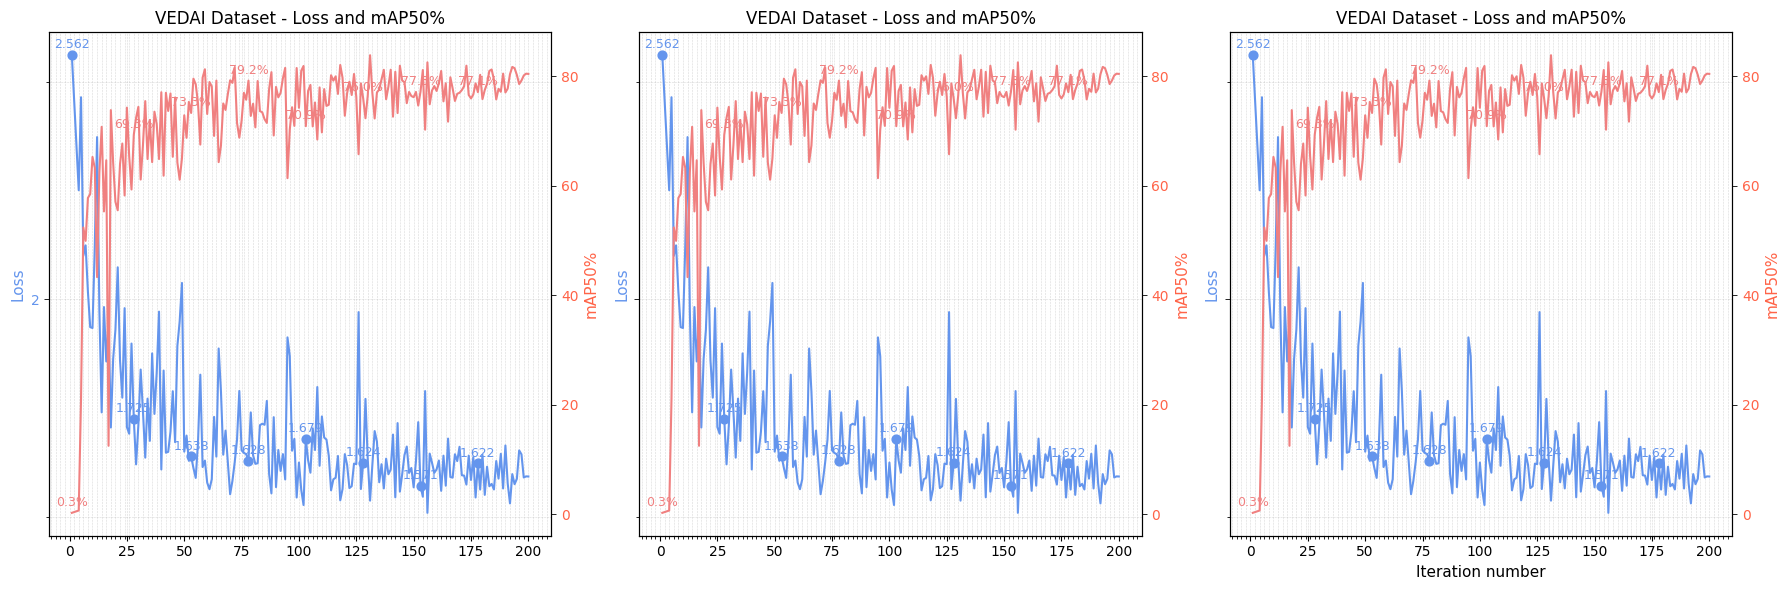

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Load CSV files
saudi_eval = pd.read_csv("/content/runs/detect/train11/results.csv")
cowc_1_eval = pd.read_csv("/content/runs/detect/train11/results.csv")
cowc_2_eval = pd.read_csv("/content/runs/detect/train11/results.csv")
synthetic_eval = pd.read_csv("/content/runs/detect/train11/results.csv")

# Keep only first 200 iterations and drop NaNs
saudi_eval = saudi_eval[saudi_eval["epoch"] <= 200].dropna(subset=["val/box_loss", "metrics/mAP50(B)"])
cowc_1_eval = cowc_1_eval[cowc_1_eval["epoch"] <= 200].dropna(subset=["val/box_loss", "metrics/mAP50(B)"])
cowc_2_eval = cowc_2_eval[cowc_2_eval["epoch"] <= 200].dropna(subset=["val/box_loss", "metrics/mAP50(B)"])
synthetic_eval = synthetic_eval[synthetic_eval["epoch"] <= 200].dropna(subset=["val/box_loss", "metrics/mAP50(B)"])

# Extract relevant columns
iterations_saudi = saudi_eval["epoch"]
loss_saudi = saudi_eval["val/box_loss"]
map50_saudi = saudi_eval["metrics/mAP50(B)"] * 100

# Adjust epoch for cowc_2_eval
last_epoch_cowc_1 = cowc_1_eval["epoch"].max()
cowc_2_eval["epoch"] = cowc_2_eval["epoch"] + last_epoch_cowc_1

# Concatenate cowc_1_eval and cowc_2_eval
cowc_eval = pd.concat([cowc_1_eval, cowc_2_eval], ignore_index=True)
cowc_eval = cowc_eval[cowc_eval["epoch"] <= 200]
iterations_cowc = cowc_eval["epoch"]
loss_cowc = cowc_eval["val/box_loss"]
map50_cowc = cowc_eval["metrics/mAP50(B)"] * 100

# Synthetic eval
iterations_synthetic = synthetic_eval["epoch"]
loss_synthetic = synthetic_eval["val/box_loss"]
map50_synthetic = synthetic_eval["metrics/mAP50(B)"] * 100

# Colors
loss_color = "#6495ED"  # Cornflower blue
map50_color = "#F08080"  # Light coral

# Create subplots
fig, axs = plt.subplots(1, 3, figsize=(18, 6), sharey=True)

# Function to plot a single subplot
def plot_eval(ax, iterations, loss, map50, title):
    ax.plot(iterations, loss, color=loss_color, linewidth=1.5, label="Loss")
    ax.set_ylabel("Loss", color=loss_color, fontsize=11)
    ax.tick_params(axis="y", labelcolor=loss_color, width=0.6)

    ax2 = ax.twinx()
    ax2.plot(iterations, map50, color=map50_color, linewidth=1.5, label="mAP50%")
    ax2.set_ylabel("mAP50%", color="#FF6347", fontsize=11)
    ax2.tick_params(axis="y", labelcolor="#FF6347", width=0.6)

    # Annotate every 25 iterations
    for i in range(0, len(iterations), 25):
        ax.scatter(iterations.iloc[i], loss.iloc[i], color=loss_color, s=40, zorder=5)
        ax.annotate(f"{loss.iloc[i]:.3f}",
                    (iterations.iloc[i], loss.iloc[i]),
                    textcoords="offset points", xytext=(0, 5), ha="center",
                    fontsize=9, color=loss_color)
        ax2.annotate(f"{map50.iloc[i]:.1f}%",
                     (iterations.iloc[i], map50.iloc[i]),
                     textcoords="offset points", xytext=(0, 5), ha="center",
                     fontsize=9, color=map50_color)

    ax.set_title(title, fontsize=12)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(25))
    ax.xaxis.set_minor_locator(ticker.MultipleLocator(2))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(2))
    ax.yaxis.set_minor_locator(ticker.MultipleLocator(0.5))
    ax.grid(which="both", linestyle="--", linewidth=0.4, color="#B0B0B0", alpha=0.5)

# Plot all three datasets
plot_eval(axs[0], iterations_saudi, loss_saudi, map50_saudi, "VEDAI Dataset - Loss and mAP50%")
plot_eval(axs[1], iterations_cowc, loss_cowc, map50_cowc, "VEDAI Dataset - Loss and mAP50%")
plot_eval(axs[2], iterations_synthetic, loss_synthetic, map50_synthetic, "VEDAI Dataset - Loss and mAP50%")

axs[2].set_xlabel("Iteration number", fontsize=11)
plt.tight_layout()
plt.show()


In [ ]:
import shutil
from google.colab import files

# Path to the folder you want to zip
folder_path = "/content/runs/detect/train11"
zip_path = "/content/train11.zip"

# Create a zip file
shutil.make_archive(base_name="/content/train11", format='zip', root_dir=folder_path)

# Download the zip file
files.download(zip_path)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

#### 1.4.1.3. Testing

In [ ]:
from ultralytics import YOLO

# model = YOLO("/content/runs/detect/train/weights/best.pt")

# Run validation on test data
results = model.val(data="/content/drive/MyDrive/vehicle_detection/vedai_dataset.yaml", split="test", imgsz=512)


Ultralytics 8.3.236 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
val: Fast image access ✅ (ping: 0.5±0.1 ms, read: 1.3±0.2 MB/s, size: 475.2 KB)
val: Scanning /content/drive/MyDrive/vehicle_detection/raw_vedai_dataset/test/labels... 68 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 68/68 1.5it/s 44.6s
val: New cache created: /content/drive/MyDrive/vehicle_detection/raw_vedai_dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 1.8it/s 2.8s
                   all         68        290      0.824      0.786      0.834      0.466
Speed: 5.3ms preprocess, 11.0ms inference, 0.0ms loss, 3.5ms postprocess per image
Results saved to /content/runs/detect/val3


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive



image 1/1 /content/drive/MyDrive/vehicle_detection/raw_vedai_dataset/test/images/00000277.png: 512x512 16 vehicles, 21.1ms
Speed: 1.5ms preprocess, 21.1ms inference, 11.2ms postprocess per image at shape (1, 3, 512, 512)


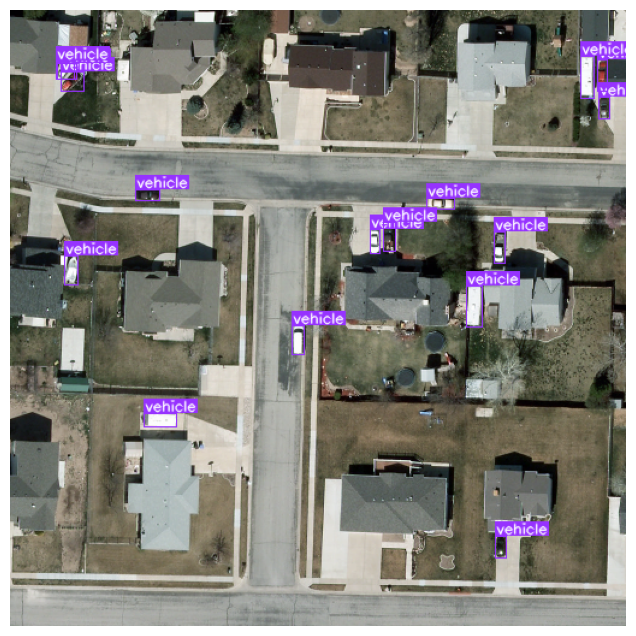

In [ ]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO

# --- Configuration (TIGHTER LABELS) ---
# Define the BGR color for the bounding boxes and text background (Purple)
PURPLE_COLOR_BGR = (255, 50, 150)
# Define the BGR color for the text (White)
TEXT_COLOR_BGR = (255, 255, 255)

TEXT_SCALE = 0.4  # Smaller font size
THICKNESS = 1     # Thinner bounding box lines
FONT = cv2.FONT_HERSHEY_SIMPLEX

# --- Model and Path Setup ---
model = YOLO("/content/drive/MyDrive/vehicle_detection/best.pt")

# Run inference on a test image
sample_image_path = "/content/drive/MyDrive/vehicle_detection/raw_vedai_dataset/test/images/00000277.png"
results = model(sample_image_path, conf=0.25)

# Load the original image
image = cv2.imread(sample_image_path)
if image is None:
    print(f"Error: Could not load image from {sample_image_path}")
    exit()

# --- Plotting and Drawing Results ---
for result in results:
    for box in result.boxes:
        # 1. Get Coordinates
        x1, y1, x2, y2 = map(int, box.xyxy[0])
        class_id = int(box.cls[0])

        # 2. Draw the Bounding Box
        cv2.rectangle(image, (x1, y1), (x2, y2), PURPLE_COLOR_BGR, THICKNESS)

        # 3. Create the Text Label (ONLY CLASS NAME)
        display_text = f"{model.names[class_id]}"

        # 4. Calculate Text Size for the Background Rectangle
        (w, h), _ = cv2.getTextSize(display_text, FONT, TEXT_SCALE, THICKNESS)

        # 5. Draw the Solid PURPLE Background Rectangle (TIGHTER PADDING)
        # Vertical padding reduced from -4 to -3.
        # Horizontal padding reduced from +2 to +1.
        cv2.rectangle(image,
                      (x1, y1 - h - 3),             # Top-left corner (Tighter vertical fit)
                      (x1 + w + 1, y1 - 1),         # Bottom-right corner (Tighter horizontal fit)
                      PURPLE_COLOR_BGR,
                      -1)

        # 6. Draw the White Text onto the Purple Background
        # Adjusted position to center the text in the new tighter box.
        cv2.putText(image,
                    display_text,
                    (x1 + 1, y1 - 2),               # Position adjusted slightly for centering
                    FONT,
                    TEXT_SCALE,
                    TEXT_COLOR_BGR,
                    THICKNESS,
                    cv2.LINE_AA)

# --- Display the Image ---
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(10, 8))
plt.imshow(image_rgb)
plt.axis("off")
plt.show()

### 1.4.2. DOTA

#### 1.4.2.1. Dataset Preparation

In [ ]:
import os
import json

base = "/content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota"

splits = ["train", "val", "test"]

# Both class types map to class 0
valid_classes = ["large vehicle", "small vehicle"]
class_id = 0   # single class only

for split in splits:

    ann_dir = os.path.join(base, split, "ann")
    out_dir = os.path.join(base, split, "raw_labels")
    os.makedirs(out_dir, exist_ok=True)

    for file in os.listdir(ann_dir):
        if not file.endswith(".json"):
            continue

        json_path = os.path.join(ann_dir, file)
        out_path = os.path.join(out_dir, file.replace(".png.json", ".txt"))

        with open(json_path, "r") as f:
            data = json.load(f)

        W = data["size"]["width"]
        H = data["size"]["height"]

        yolo_lines = []

        for obj in data["objects"]:
            cls = obj["classTitle"].lower()

            # Keep only vehicles
            if cls not in valid_classes:
                continue

            points = obj["points"]["exterior"]

            # polygon → bounding box
            xs = [p[0] for p in points]
            ys = [p[1] for p in points]

            xmin, xmax = min(xs), max(xs)
            ymin, ymax = min(ys), max(ys)

            x_center = (xmin + xmax) / 2 / W
            y_center = (ymin + ymax) / 2 / H
            width = (xmax - xmin) / W
            height = (ymax - ymin) / H

            yolo_lines.append(f"{class_id} {x_center} {y_center} {width} {height}\n")

        # Save label file even if empty
        with open(out_path, "w") as f:
            f.writelines(yolo_lines)

    print(f"✔ Finished {split} — labels saved in {out_dir}")


✔ Finished train — labels saved in /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/train/raw_labels
✔ Finished val — labels saved in /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/val/raw_labels
✔ Finished test — labels saved in /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/test/raw_labels


In [ ]:
import os

base = "/content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota"
splits = ["train", "val", "test"]

for split in splits:
    print("\n====== Checking split:", split, "======")

    img_dir = os.path.join(base, split, "img")
    label_dir = os.path.join(base, split, "raw_labels")

    image_files = {f.replace(".png", "") for f in os.listdir(img_dir) if f.endswith(".png")}
    label_files = {f.replace(".txt", "") for f in os.listdir(label_dir) if f.endswith(".txt")}

    # 1. Images without labels → delete image
    only_images = image_files - label_files

    for name in sorted(only_images):
        img_path = os.path.join(img_dir, name + ".png")
        os.remove(img_path)
        print(f"Deleted image (no label): {img_path}")

    # 2. Labels without images → delete label
    only_labels = label_files - image_files

    for name in sorted(only_labels):
        txt_path = os.path.join(label_dir, name + ".txt")
        os.remove(txt_path)
        print(f"Deleted label (no image): {txt_path}")

    # Refresh after deletion
    image_files = {f.replace(".png", "") for f in os.listdir(img_dir) if f.endswith(".png")}
    label_files = {f.replace(".txt", "") for f in os.listdir(label_dir) if f.endswith(".txt")}

    # 3. Empty labels → delete both label and image
    for name in sorted(label_files):
        txt_path = os.path.join(label_dir, name + ".txt")

        # If label empty → delete both
        if os.path.getsize(txt_path) == 0:
            img_path = os.path.join(img_dir, name + ".png")

            if os.path.exists(img_path):
                os.remove(img_path)
                print(f"Deleted image (empty label): {img_path}")

            os.remove(txt_path)
            print(f"Deleted empty label: {txt_path}")

    print("✔ Done checking", split)



====== Checking split: train ======
Deleted image (empty label): /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/train/img/P0482.png
Deleted empty label: /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/train/raw_labels/P0482.txt
Deleted image (empty label): /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/train/img/P10250.png
Deleted empty label: /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/train/raw_labels/P10250.txt
Deleted image (empty label): /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/train/img/P10909.png
Deleted empty label: /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/train/raw_labels/P10909.txt
Deleted image (empty label): /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/train/img/P1228.png
Deleted empty label: /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/train/raw_labels/P1228.txt
Deleted image (empty label): /content/drive/MyDrive/vehicle_detecti

In [ ]:
import os

base = "/content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota"
splits = ["train", "val", "test"]

for split in splits:
    img_dir = os.path.join(base, split, "img")
    label_dir = os.path.join(base, split, "raw_labels")

    num_images = len([f for f in os.listdir(img_dir) if f.endswith(".png")])
    num_labels = len([f for f in os.listdir(label_dir) if f.endswith(".txt")])

    print(f"{split}: {num_images} images, {num_labels} labels")


train: 36 images, 36 labels
val: 14 images, 14 labels
test: 0 images, 0 labels


#### 1.4.2.2. Training

In [ ]:
import os
from PIL import Image

val_img_dir = "/content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/val/img"

for file in sorted(os.listdir(val_img_dir)):
    if file.endswith(".png"):
        img_path = os.path.join(val_img_dir, file)
        img = Image.open(img_path)
        w, h = img.size  # PIL gives size as (width, height)
        print(f"{file}: height={h}, width={w}, channels={len(img.getbands())}")


P0168.png: height=1792, width=2304, channels=3
P0524.png: height=1106, width=1103, channels=3
P0665.png: height=1680, width=1294, channels=3
P0749.png: height=824, width=1439, channels=3
P0977.png: height=2217, width=2053, channels=3
P1380.png: height=4694, width=4397, channels=3
P1513.png: height=4138, width=2652, channels=3
P1903.png: height=1288, width=1946, channels=3
P2241.png: height=1072, width=736, channels=3
P2342.png: height=2374, width=1914, channels=3
P2450.png: height=1680, width=1680, channels=3
P2630.png: height=1396, width=1830, channels=3
P5171.png: height=4096, width=4096, channels=3
P9997.png: height=4096, width=4096, channels=3


In [ ]:
import os

base = "/content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota"
splits = ["train", "val", "test"]

for split in splits:
    split_path = os.path.join(base, split)

    old_img = os.path.join(split_path, "img")
    new_img = os.path.join(split_path, "images")

    old_lbl = os.path.join(split_path, "raw_labels")
    new_lbl = os.path.join(split_path, "labels")

    # Rename images folder
    if os.path.exists(old_img):
        os.rename(old_img, new_img)
        print(f"Renamed: {old_img} → {new_img}")
    else:
        print(f"Missing folder: {old_img}")

    # Rename labels folder
    if os.path.exists(old_lbl):
        os.rename(old_lbl, new_lbl)
        print(f"Renamed: {old_lbl} → {new_lbl}")
    else:
        print(f"Missing folder: {old_lbl}")


Renamed: /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/train/img → /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/train/images
Renamed: /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/train/raw_labels → /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/train/labels
Renamed: /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/val/img → /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/val/images
Renamed: /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/val/raw_labels → /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/val/labels
Renamed: /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/test/img → /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/test/images
Renamed: /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/test/raw_labels → /content/drive/MyDrive/vehicle_detection/raw_dota_dataset/Dota/test/labels


In [ ]:
from ultralytics import YOLO
model = YOLO("yolo12s.pt")

results = model.train(data="/content/drive/MyDrive/vehicle_detection/dota_dataset.yaml", epochs=50, imgsz=512)


Ultralytics 8.3.235 🚀 Python-3.12.12 torch-2.9.0+cu126 CUDA:0 (Tesla T4, 15095MiB)
engine/trainer: agnostic_nms=False, amp=True, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, classes=None, close_mosaic=10, cls=0.5, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/vehicle_detection/dota_dataset.yaml, degrees=0.0, deterministic=True, device=None, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=512, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo12s.pt, momentum=0.937, mosaic=1.0, multi_scale=False, name=train8, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, pers

In [ ]:
from ultralytics import YOLO

# Run validation on test data
results = model.val(data="/content/drive/MyDrive/vehicle_detection/dota_dataset.yaml", split="val", imgsz=512)


# Retina Net

In [4]:
import torchvision
print(torchvision.__version__)


0.24.0+cu126


In [ ]:
import os
import glob
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision.io import read_image
from torchvision.models.detection import retinanet_resnet50_fpn

# ================================================================
# Debug print helper
# ================================================================
def debug(msg):
    print(f"[DEBUG] {msg}")

# ================================================================
# Dataset
# ================================================================
class YOLODataset(Dataset):
    def __init__(self, images_dir, labels_dir):
        self.images = sorted(glob.glob(os.path.join(images_dir, "*.png")))
        self.labels_dir = labels_dir
        debug(f"Dataset created: {len(self.images)} images loaded from {images_dir}")

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):
        img_path = self.images[idx]
        label_path = os.path.join(
            self.labels_dir, os.path.basename(img_path).replace(".png", ".txt")
        )

        img = read_image(img_path).float() / 255.0

        # Fix RGBA → RGB
        if img.shape[0] == 4:
            img = img[:3, :, :]

        h, w = img.shape[1], img.shape[2]

        boxes = []
        labels = []

        if os.path.exists(label_path):
            with open(label_path, "r") as f:
                for line in f:
                    cls, xc, yc, bw, bh = map(float, line.strip().split())
                    xmin = (xc - bw / 2) * w
                    xmax = (xc + bw / 2) * w
                    ymin = (yc - bh / 2) * h
                    ymax = (yc + bh / 2) * h
                    boxes.append([xmin, ymin, xmax, ymax])
                    labels.append(1)

        # Fix empty labels
        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes = torch.tensor(boxes, dtype=torch.float32)
            labels = torch.tensor(labels, dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels
        }

        return img, target

def collate_fn(batch):
    return tuple(zip(*batch))

# ================================================================
# Paths
# ================================================================
train_imgs = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/train/images"
train_lbls = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/train/labels"

val_imgs = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/val/images"
val_lbls = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/val/labels"

train_dataset = YOLODataset(train_imgs, train_lbls)
val_dataset = YOLODataset(val_imgs, val_lbls)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, collate_fn=collate_fn)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
debug(f"Using device: {device}")

# ================================================================
# RetinaNet Fix
# ================================================================
debug("Loading RetinaNet model...")
model = retinanet_resnet50_fpn(weights=None)

num_classes = 2
num_anchors = model.head.classification_head.num_anchors
in_features = model.head.classification_head.cls_logits.in_channels

model.head.classification_head.cls_logits = nn.Conv2d(
    in_features,
    num_anchors * num_classes,
    kernel_size=3,
    padding=1
)
model.head.classification_head.num_classes = num_classes

debug("RetinaNet classification head replaced with correct output channels.")
model.to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# ================================================================
# Training Loop with loss logging and best model saving
# ================================================================
best_loss = float('inf')  # initialize best loss
loss_log_file = "/content/drive/MyDrive/vehicle_detection/loss_log.txt"

# Clear previous log
with open(loss_log_file, "w") as f:
    f.write("Epoch,TotalLoss\n")

for epoch in range(10):
    debug(f"\n=============== EPOCH {epoch+1} START ===============")
    model.train()
    total_loss = 0

    for batch_i, (images, targets) in enumerate(train_loader):
        debug(f"\n--- Batch {batch_i} ---")
        debug(f"Number of images in batch = {len(images)}")

        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        # Forward pass
        loss_dict = model(images, targets)
        losses = sum(loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        total_loss += losses.item()
        debug(f"Batch {batch_i} loss = {losses.item():.4f}")

    # Save epoch loss to file
    with open(loss_log_file, "a") as f:
        f.write(f"{epoch+1},{total_loss:.4f}\n")

    print(f"Epoch {epoch+1} Loss = {total_loss:.4f}")

    # Save best model
    if total_loss < best_loss:
        best_loss = total_loss
        torch.save(model.state_dict(), "/content/drive/MyDrive/vehicle_detection/best_model.pth")
        print(f"--> Best model saved at epoch {epoch+1} with loss {best_loss:.4f}")


[DEBUG] Dataset created: 317 images loaded from /content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/train/images
[DEBUG] Dataset created: 71 images loaded from /content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/val/images
[DEBUG] Using device: cuda
[DEBUG] Loading RetinaNet model...
Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth


100%|██████████| 97.8M/97.8M [00:00<00:00, 162MB/s]


[DEBUG] RetinaNet classification head replaced with correct output channels.
[DEBUG] 
=============== EPOCH 1 START ===============
[DEBUG] 
--- Batch 0 ---
[DEBUG] Number of images in batch = 16
[DEBUG] Batch 0 loss = 119.3605
[DEBUG] 
--- Batch 1 ---
[DEBUG] Number of images in batch = 16
[DEBUG] Batch 1 loss = 2044.1522
[DEBUG] 
--- Batch 2 ---
[DEBUG] Number of images in batch = 16
[DEBUG] Batch 2 loss = 3416.7385
[DEBUG] 
--- Batch 3 ---
[DEBUG] Number of images in batch = 16
[DEBUG] Batch 3 loss = 29.1578
[DEBUG] 
--- Batch 4 ---
[DEBUG] Number of images in batch = 16
[DEBUG] Batch 4 loss = 175.4399
[DEBUG] 
--- Batch 5 ---
[DEBUG] Number of images in batch = 16
[DEBUG] Batch 5 loss = 3.0493
[DEBUG] 
--- Batch 6 ---
[DEBUG] Number of images in batch = 16
[DEBUG] Batch 6 loss = 7.0187
[DEBUG] 
--- Batch 7 ---
[DEBUG] Number of images in batch = 16
[DEBUG] Batch 7 loss = 13.2794
[DEBUG] 
--- Batch 8 ---
[DEBUG] Number of images in batch = 16
[DEBUG] Batch 8 loss = 23.9099
[DEBUG] 


In [ ]:
import torch
import torch.optim as optim
from torchvision.models.detection import retinanet_resnet50_fpn

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ================================================================
# 1. Recreate model architecture EXACTLY the same as before
# ================================================================
model = retinanet_resnet50_fpn(weights=None)

num_classes = 2
num_anchors = model.head.classification_head.num_anchors
in_features = model.head.classification_head.cls_logits.in_channels

model.head.classification_head.cls_logits = nn.Conv2d(
    in_features,
    num_anchors * num_classes,
    kernel_size=3,
    padding=1
)
model.head.classification_head.num_classes = num_classes

# ================================================================
# 2. Load best model weights
# ================================================================
best_model_path = "/content/drive/MyDrive/vehicle_detection/best_model_continued.pth"
model.load_state_dict(torch.load(best_model_path))
model.to(device)

print("✔ Loaded best model and ready to continue training!")

# ================================================================
# 3. Recreate optimizer
# ================================================================
optimizer = optim.Adam(model.parameters(), lr=1e-4)

# ================================================================
# 4. Continue training more epochs
# ================================================================
more_epochs = 85   # change to your need

for epoch in range(more_epochs):
    print(f"\n===== CONTINUED EPOCH {epoch+1} =====")
    model.train()
    total_loss = 0

    for images, targets in train_loader:
        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        loss_dict = model(images, targets)
        losses = sum(loss_dict.values())

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        total_loss += losses.item()

    print(f"Epoch Loss = {total_loss:.4f}")

# Save updated model
torch.save(model.state_dict(), "/content/drive/MyDrive/vehicle_detection/best_model_retinanet.pth")
print("✔ Continued training finished and model saved!")


✔ Loaded best model and ready to continue training!

===== CONTINUED EPOCH 1 =====
Epoch Loss = 25.6758

===== CONTINUED EPOCH 2 =====
Epoch Loss = 19.8455

===== CONTINUED EPOCH 3 =====
Epoch Loss = 16.6529

===== CONTINUED EPOCH 4 =====
Epoch Loss = 14.2058

===== CONTINUED EPOCH 5 =====
Epoch Loss = 12.8015

===== CONTINUED EPOCH 6 =====
Epoch Loss = 10.9040

===== CONTINUED EPOCH 7 =====
Epoch Loss = 9.3656

===== CONTINUED EPOCH 8 =====
Epoch Loss = 8.4583

===== CONTINUED EPOCH 9 =====
Epoch Loss = 7.4734

===== CONTINUED EPOCH 10 =====
Epoch Loss = 6.7086

===== CONTINUED EPOCH 11 =====
Epoch Loss = 6.2354

===== CONTINUED EPOCH 12 =====
Epoch Loss = 5.7155

===== CONTINUED EPOCH 13 =====
Epoch Loss = 5.3150

===== CONTINUED EPOCH 14 =====
Epoch Loss = 4.8371

===== CONTINUED EPOCH 15 =====
Epoch Loss = 4.6748

===== CONTINUED EPOCH 16 =====
Epoch Loss = 4.2478

===== CONTINUED EPOCH 17 =====
Epoch Loss = 4.4117

===== CONTINUED EPOCH 18 =====
Epoch Loss = 4.1036

===== CONTINUE

In [ ]:
import os
import glob
import torch
import numpy as np
from torchvision.ops import box_iou
from torchvision.io import read_image
from torchvision.models.detection import retinanet_resnet50_fpn
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ================================================================
# Load Best Model
# ================================================================
print("Loading best model...")
model = retinanet_resnet50_fpn(weights=None)

num_classes = 2
num_anchors = model.head.classification_head.num_anchors
in_features = model.head.classification_head.cls_logits.in_channels

model.head.classification_head.cls_logits = torch.nn.Conv2d(
    in_features, num_anchors * num_classes, kernel_size=3, padding=1
)
model.head.classification_head.num_classes = num_classes

model.load_state_dict(torch.load("/content/drive/MyDrive/vehicle_detection/best_model_retinanet.pth"))
model.to(device)
model.eval()

# ================================================================
# Dataset paths
# ================================================================
val_imgs = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/val/images"
val_lbls = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/val/labels"
test_imgs = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/test/images"
test_lbls = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/test/labels"

# ================================================================
# Helper: Read YOLO label → xyxy
# ================================================================
def read_yolo_labels(label_path, img_w, img_h):
    boxes = []
    if not os.path.exists(label_path):
        return torch.zeros((0, 4))

    with open(label_path, "r") as f:
        for line in f:
            cls, xc, yc, w, h = map(float, line.split())
            xmin = (xc - w/2) * img_w
            xmax = (xc + w/2) * img_w
            ymin = (yc - h/2) * img_h
            ymax = (yc + h/2) * img_h
            boxes.append([xmin, ymin, xmax, ymax])
    return torch.tensor(boxes)


# ================================================================
# Evaluation + Confusion Matrix
# ================================================================
def evaluate_dataset(images_dir, labels_dir):

    tp, fp, fn = 0, 0, 0
    all_ap = []

    image_paths = sorted(glob.glob(os.path.join(images_dir, "*.png")))
    print(f"\nEvaluating {len(image_paths)} images from {images_dir}")

    for img_path in image_paths:

        img = read_image(img_path).float() / 255.0
        if img.shape[0] == 4:
            img = img[:3, :, :]

        H, W = img.shape[1], img.shape[2]
        label_path = os.path.join(labels_dir, os.path.basename(img_path).replace(".png", ".txt"))
        gt_boxes = read_yolo_labels(label_path, W, H).float()

        with torch.no_grad():
            preds = model([img.to(device)])

        pred_boxes = preds[0]["boxes"].cpu()
        scores = preds[0]["scores"].cpu()

        # Filter predictions by confidence
        keep = scores > 0.5
        pred_boxes = pred_boxes[keep]

        # Case: no GT
        if len(gt_boxes) == 0:
            fp += len(pred_boxes)
            continue

        # Case: no predictions
        if len(pred_boxes) == 0:
            fn += len(gt_boxes)
            continue

        ious = box_iou(pred_boxes, gt_boxes)
        matched_pred = set()
        matched_gt = set()

        for i in range(len(pred_boxes)):
            for j in range(len(gt_boxes)):
                if ious[i, j] > 0.5:
                    matched_pred.add(i)
                    matched_gt.add(j)

        tp += len(matched_pred)
        fp += len(pred_boxes) - len(matched_pred)
        fn += len(gt_boxes) - len(matched_gt)

        # Per image AP50
        all_ap.append(1.0 if len(matched_pred) > 0 else 0.0)

    # Final metrics
    precision = tp / (tp + fp + 1e-6)
    recall = tp / (tp + fn + 1e-6)
    f1 = 2 * precision * recall / (precision + recall + 1e-6)
    mAP50 = np.mean(all_ap)

    # Confusion matrix (TN = 0 in detection)
    confusion = pd.DataFrame(
        [[tp, fp], [fn, 0]],
        columns=["Predicted Positive", "Predicted Negative"],
        index=["Actual Positive", "Actual Negative"]
    )

    return precision, recall, f1, mAP50, confusion


# ================================================================
# Run evaluation for VAL and TEST
# ================================================================
val_p, val_r, val_f1, val_map, val_conf = evaluate_dataset(val_imgs, val_lbls)
test_p, test_r, test_f1, test_map, test_conf = evaluate_dataset(test_imgs, test_lbls)

# ================================================================
# Print Results
# ================================================================
print("\n========= VALIDATION RESULTS =========")
print(f"Precision: {val_p:.4f}")
print(f"Recall:    {val_r:.4f}")
print(f"F1 Score:  {val_f1:.4f}")
print(f"mAP50:     {val_map:.4f}")
print("\nValidation Confusion Matrix:")
print(val_conf)

print("\n========= TEST RESULTS =========")
print(f"Precision: {test_p:.4f}")
print(f"Recall:    {test_r:.4f}")
print(f"F1 Score:  {test_f1:.4f}")
print(f"mAP50:     {test_map:.4f}")
print("\nTest Confusion Matrix:")
print(test_conf)


Loading best model...

Evaluating 71 images from /content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/val/images

Evaluating 112 images from /content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/test/images

========= VALIDATION RESULTS =========
Precision: 0.9125
Recall:    0.9413
F1 Score:  0.9267
mAP50:     0.9857

Validation Confusion Matrix:
                 Predicted Positive  Predicted Negative
Actual Positive                1106                 106
Actual Negative                  69                   0

========= TEST RESULTS =========
Precision: 0.9027
Recall:    0.9257
F1 Score:  0.9141
mAP50:     1.0000

Test Confusion Matrix:
                 Predicted Positive  Predicted Negative
Actual Positive                1021                 110
Actual Negative                  82                   0


# Faster CNN

In [ ]:
import os
import glob
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision.io import read_image


# ================================================================
# Dataset
# ================================================================
class YOLODataset(Dataset):
    def __init__(self, images_dir, labels_dir):
        self.images = sorted(glob.glob(os.path.join(images_dir, "*.png")))
        self.labels_dir = labels_dir

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        img_path = self.images[idx]
        label_path = os.path.join(
            self.labels_dir, os.path.basename(img_path).replace(".png", ".txt")
        )

        img = read_image(img_path).float() / 255.0

        # remove alpha channel if PNG is RGBA
        if img.shape[0] == 4:
            img = img[:3]

        h, w = img.shape[1], img.shape[2]

        boxes = []
        labels = []

        # read YOLO labels
        if os.path.exists(label_path):
            with open(label_path, "r") as f:
                for line in f:
                    cls, xc, yc, bw, bh = map(float, line.strip().split())
                    xmin = (xc - bw / 2) * w
                    xmax = (xc + bw / 2) * w
                    ymin = (yc - bh / 2) * h
                    ymax = (yc + bh / 2) * h
                    boxes.append([xmin, ymin, xmax, ymax])
                    labels.append(1)

        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
        else:
            boxes = torch.tensor(boxes, dtype=torch.float32)
            labels = torch.tensor(labels, dtype=torch.int64)

        return img, {"boxes": boxes, "labels": labels}


def collate_fn(batch):
    return tuple(zip(*batch))


# ================================================================
# Fast CNN Detector (lightweight)
# ================================================================
class FastCNNDetector(nn.Module):
    def __init__(self, num_classes=2, max_boxes=20):
        super().__init__()
        self.max_boxes = max_boxes
        self.num_classes = num_classes

        # Backbone CNN
        self.backbone = nn.Sequential(
            nn.Conv2d(3, 16, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(16, 32, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(32, 64, 3, stride=2, padding=1), nn.ReLU(),
            nn.Conv2d(64, 128, 3, stride=2, padding=1), nn.ReLU()
        )

        # Pool and FC
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Linear(128, 256)

        # Detection heads
        self.box_head = nn.Linear(256, max_boxes * 4)      # bounding boxes
        self.cls_head = nn.Linear(256, max_boxes * num_classes)  # classes

    def forward(self, images, targets=None):
        device = images[0].device
        total_loss = torch.tensor(0.0, device=device)
        predictions = []

        for img, target in zip(images, targets):

            # CNN forward
            feat = self.backbone(img.unsqueeze(0))
            feat = self.pool(feat).view(1, -1)
            feat = self.fc(feat)

            # Predictions
            pred_boxes = self.box_head(feat).view(self.max_boxes, 4)
            pred_class = self.cls_head(feat).view(self.max_boxes, self.num_classes)

            predictions.append({"boxes": pred_boxes, "scores": pred_class})

            # Loss
            if target["boxes"].shape[0] > 0:
                n = min(target["boxes"].shape[0], self.max_boxes)

                total_loss += nn.functional.l1_loss(
                    pred_boxes[:n], target["boxes"][:n]
                )

                total_loss += nn.functional.cross_entropy(
                    pred_class[:n],
                    target["labels"][:n]
                )

        return predictions, {"loss": total_loss}


# ================================================================
# Load data
# ================================================================
train_imgs = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/train/images"
train_lbls = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/train/labels"

val_imgs = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/val/images"
val_lbls = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/val/labels"

train_dataset = YOLODataset(train_imgs, train_lbls)
val_dataset = YOLODataset(val_imgs, val_lbls)

train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, collate_fn=collate_fn)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ================================================================
# Model + Optimizer
# ================================================================
model = FastCNNDetector(num_classes=2).to(device)
optimizer = optim.Adam(model.parameters(), lr=3e-4)


# ================================================================
# Prepare logging
# ================================================================
log_path = "/content/drive/MyDrive/vehicle_detection/faster_cnn_log.txt"
best_model_path = "/content/drive/MyDrive/vehicle_detection/best_model_faster_cnn.pth"

# clear previous log
open(log_path, "w").close()

def write_log(msg):
    print(msg)
    with open(log_path, "a") as f:
        f.write(msg + "\n")


# ================================================================
# Training Loop + Validation + Save Best Model
# ================================================================
best_val_loss = float("inf")

for epoch in range(100):
    write_log("\n==============================================")
    write_log(f"🚀 EPOCH {epoch + 1} START")
    write_log("==============================================")

    # ---------- TRAIN ----------
    model.train()
    total_loss = 0

    for batch_i, (images, targets) in enumerate(train_loader):
        write_log(f"\n🔹 Batch {batch_i} start")
        write_log(f"   → Number of images: {len(images)}")

        images = [img.to(device) for img in images]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        preds, loss_dict = model(images, targets)
        losses = sum(loss_dict.values())

        write_log(f"   → Total batch loss: {losses.item():.6f}")

        optimizer.zero_grad()
        losses.backward()
        optimizer.step()

        total_loss += losses.item()

    write_log(f"📌 Epoch {epoch + 1} Finished. Total Train Loss = {total_loss:.4f}")

    # ---------- VALIDATION ----------
    model.eval()
    val_loss = 0

    with torch.no_grad():
        for images, targets in val_loader:
            images = [img.to(device) for img in images]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            preds, loss_dict = model(images, targets)
            val_loss += sum(loss_dict.values()).item()

    write_log(f"🔍 Validation Loss = {val_loss:.4f}")

    # ---------- SAVE BEST MODEL ----------
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_model_path)
        write_log(f"💾 Best model updated! Saved to {best_model_path}")


In [ ]:
import os
import glob
import torch
import numpy as np
from torchvision.ops import box_iou
from torchvision.io import read_image
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ================================================================
# Load FastCNNDetector Model
# ================================================================
class FastCNNDetector(torch.nn.Module):
    def __init__(self, num_classes=2, max_boxes=20):
        super().__init__()
        self.max_boxes = max_boxes
        self.num_classes = num_classes

        self.backbone = torch.nn.Sequential(
            torch.nn.Conv2d(3, 16, 3, stride=2, padding=1), torch.nn.ReLU(),
            torch.nn.Conv2d(16, 32, 3, stride=2, padding=1), torch.nn.ReLU(),
            torch.nn.Conv2d(32, 64, 3, stride=2, padding=1), torch.nn.ReLU(),
            torch.nn.Conv2d(64, 128, 3, stride=2, padding=1), torch.nn.ReLU()
        )

        self.pool = torch.nn.AdaptiveAvgPool2d(1)
        self.fc = torch.nn.Linear(128, 256)

        self.box_head = torch.nn.Linear(256, max_boxes * 4)
        self.cls_head = torch.nn.Linear(256, max_boxes * num_classes)

    def forward(self, images):
        preds = []
        for img in images:
            feat = self.backbone(img.unsqueeze(0))
            feat = self.pool(feat).view(1, -1)
            feat = self.fc(feat)

            pred_boxes = self.box_head(feat).view(self.max_boxes, 4)
            pred_scores = self.cls_head(feat).view(self.max_boxes, self.num_classes)

            pred_scores = torch.softmax(pred_scores, dim=1)
            conf = pred_scores[:, 1]     # class 1 confidence

            preds.append({
                "boxes": pred_boxes,
                "scores": conf
            })
        return preds


# Load best saved model
print("Loading Fast CNN best model...")
model = FastCNNDetector(num_classes=2).to(device)
model.load_state_dict(torch.load("/content/drive/MyDrive/vehicle_detection/best_model_faster_cnn.pth"))
model.eval()

# ================================================================
# Dataset paths
# ================================================================
val_imgs = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/val/images"
val_lbls = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/val/labels"
test_imgs = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/test/images"
test_lbls = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/test/labels"

# ================================================================
# Helper: Read YOLO label → xyxy
# ================================================================
def read_yolo_labels(label_path, img_w, img_h):
    boxes = []
    if not os.path.exists(label_path):
        return torch.zeros((0, 4))

    with open(label_path, "r") as f:
        for line in f:
            cls, xc, yc, w, h = map(float, line.split())
            xmin = (xc - w / 2) * img_w
            xmax = (xc + w / 2) * img_w
            ymin = (yc - h / 2) * img_h
            ymax = (yc + h / 2) * img_h
            boxes.append([xmin, ymin, xmax, ymax])

    return torch.tensor(boxes)


# ================================================================
# Evaluation
# ================================================================
def evaluate_dataset(images_dir, labels_dir):

    tp = fp = fn = 0
    all_ap = []

    image_paths = sorted(glob.glob(os.path.join(images_dir, "*.png")))
    print(f"\nEvaluating {len(image_paths)} images...")

    for img_path in image_paths:

        img = read_image(img_path).float() / 255.0
        if img.shape[0] == 4:
            img = img[:3]

        H, W = img.shape[1], img.shape[2]

        label_path = os.path.join(
            labels_dir,
            os.path.basename(img_path).replace(".png", ".txt")
        )

        gt_boxes = read_yolo_labels(label_path, W, H).float()

        with torch.no_grad():
            preds = model([img.to(device)])

        pred_boxes = preds[0]["boxes"].cpu()
        pred_scores = preds[0]["scores"].cpu()

        # Threshold predictions
        keep = pred_scores > 0.5
        pred_boxes = pred_boxes[keep]

        # No GT
        if len(gt_boxes) == 0:
            fp += len(pred_boxes)
            continue

        # No predictions
        if len(pred_boxes) == 0:
            fn += len(gt_boxes)
            continue

        ious = box_iou(pred_boxes, gt_boxes)
        matched_pred = set()
        matched_gt = set()

        for i in range(len(pred_boxes)):
            for j in range(len(gt_boxes)):
                if ious[i, j] > 0.5:
                    matched_pred.add(i)
                    matched_gt.add(j)

        tp += len(matched_pred)
        fp += len(pred_boxes) - len(matched_pred)
        fn += len(gt_boxes) - len(matched_gt)

        # AP50 per image
        all_ap.append(1.0 if len(matched_pred) > 0 else 0.0)

    # Final metrics
    precision = tp / (tp + fp + 1e-6)
    recall = tp / (tp + fn + 1e-6)
    f1 = 2 * precision * recall / (precision + recall + 1e-6)
    mAP50 = np.mean(all_ap)

    confusion = pd.DataFrame(
        [[tp, fp], [fn, 0]],
        columns=["Predicted Positive", "Predicted Negative"],
        index=["Actual Positive", "Actual Negative"]
    )

    return precision, recall, f1, mAP50, confusion


# ================================================================
# Run evaluation for VAL and TEST
# ================================================================
val_p, val_r, val_f1, val_map, val_conf = evaluate_dataset(val_imgs, val_lbls)
test_p, test_r, test_f1, test_map, test_conf = evaluate_dataset(test_imgs, test_lbls)

# ================================================================
# Print Results
# ================================================================
print("\n========= VALIDATION RESULTS =========")
print(f"Precision: {val_p:.4f}")
print(f"Recall:    {val_r:.4f}")
print(f"F1 Score:  {val_f1:.4f}")
print(f"mAP50:     {val_map:.4f}")
print("\nValidation Confusion Matrix:")
print(val_conf)

print("\n========= TEST RESULTS =========")
print(f"Precision: {test_p:.4f}")
print(f"Recall:    {test_r:.4f}")
print(f"F1 Score:  {test_f1:.4f}")
print(f"mAP50:     {test_map:.4f}")
print("\nTest Confusion Matrix:")
print(test_conf)


Loading Fast CNN best model...

Evaluating 71 images...

Evaluating 112 images...

========= VALIDATION RESULTS =========
Precision: 0.0197
Recall:    0.0239
F1 Score:  0.0216
mAP50:     0.1571

Validation Confusion Matrix:
                 Predicted Positive  Predicted Negative
Actual Positive                  28                1392
Actual Negative                1143                   0

========= TEST RESULTS =========
Precision: 0.0076
Recall:    0.0154
F1 Score:  0.0102
mAP50:     0.0826

Test Confusion Matrix:
                 Predicted Positive  Predicted Negative
Actual Positive                  17                2223
Actual Negative                1086                   0


In [ ]:
import os
import glob
import torch
import torchvision
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision.io import read_image
from torchvision.models.detection import fasterrcnn_resnet50_fpn


# ================================================================
# Dataset (YOLO TXT → Faster R CNN format)
# ================================================================
class YOLODataset(Dataset):
    def __init__(self, images_dir, labels_dir):
        self.images = sorted(glob.glob(os.path.join(images_dir, "*.png")))
        self.labels_dir = labels_dir

    def __len__(self):
        return len(self.images)

    def __getitem__(self, idx):

        img_path = self.images[idx]
        label_path = os.path.join(
            self.labels_dir,
            os.path.basename(img_path).replace(".png", ".txt")
        )

        img = read_image(img_path).float() / 255.0

        # Remove alpha if RGBA
        if img.shape[0] == 4:
            img = img[:3]

        h, w = img.shape[1], img.shape[2]

        boxes = []
        labels = []

        # Load YOLO TXT
        if os.path.exists(label_path):
            with open(label_path, "r") as f:
                for line in f:
                    values = line.strip().split()
                    if len(values) != 5:
                        continue
                    cls, xc, yc, bw, bh = map(float, values)

                    xmin = (xc - bw / 2) * w
                    xmax = (xc + bw / 2) * w
                    ymin = (yc - bh / 2) * h
                    ymax = (yc + bh / 2) * h

                    # Skip invalid boxes
                    if xmin >= xmax or ymin >= ymax:
                        continue

                    boxes.append([xmin, ymin, xmax, ymax])
                    labels.append(1)   # Only 1 class

        # ---- Fix empty images ----
        if len(boxes) == 0:
            boxes = torch.zeros((0, 4), dtype=torch.float32)
            labels = torch.zeros((0,), dtype=torch.int64)
            area = torch.zeros((0,), dtype=torch.float32)
        else:
            boxes = torch.tensor(boxes, dtype=torch.float32)
            labels = torch.tensor(labels, dtype=torch.int64)
            area = (boxes[:, 2] - boxes[:, 0]) * (boxes[:, 3] - boxes[:, 1])

        iscrowd = torch.zeros((len(labels),), dtype=torch.int64)

        target = {
            "boxes": boxes,
            "labels": labels,
            "area": area,
            "iscrowd": iscrowd,
        }

        return img, target


# ================================================================
# Collate FN
# ================================================================
def collate_fn(batch):
    return tuple(zip(*batch))


# ================================================================
# Paths
# ================================================================
train_imgs = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/train/images"
train_lbls = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/train/labels"

val_imgs = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/val/images"
val_lbls = "/content/drive/MyDrive/vehicle_detection/saudi_vehicle_dataset/val/labels"


# ================================================================
# Load datasets
# ================================================================
train_dataset = YOLODataset(train_imgs, train_lbls)
val_dataset = YOLODataset(val_imgs, val_lbls)

train_loader = DataLoader(train_dataset, batch_size=4, shuffle=True, collate_fn=collate_fn)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, collate_fn=collate_fn)


# ================================================================
# Model
# ================================================================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = fasterrcnn_resnet50_fpn(pretrained=True)

in_features = model.roi_heads.box_predictor.cls_score.in_features
model.roi_heads.box_predictor = torchvision.models.detection.faster_rcnn.FastRCNNPredictor(
    in_features,
    num_classes=2
)

model = model.to(device)
optimizer = optim.Adam(model.parameters(), lr=1e-4)


# ================================================================
# Helper: ensure target is valid for loss computation
# ================================================================
def is_valid_target(t):
    if "boxes" not in t or "labels" not in t:
        return False
    if t["boxes"].ndim != 2 or t["boxes"].shape[1] != 4:
        return False
    if t["boxes"].shape[0] == 0:
        return False
    if (t["boxes"][:, 2] <= t["boxes"][:, 0]).any():
        return False
    if (t["boxes"][:, 3] <= t["boxes"][:, 1]).any():
        return False
    return True


# ================================================================
# TRAINING LOOP
# ================================================================
best_val_loss = float("inf")
best_model_path = "/content/drive/MyDrive/vehicle_detection/best_faster_rcnn.pth"

for epoch in range(20):
    print(f"\n===============================")
    print(f"🚀 EPOCH {epoch + 1}")
    print("===============================")

    # -----------------------------
    # TRAIN
    # -----------------------------
    model.train()
    train_loss = 0

    for imgs, targets in train_loader:
        imgs = [img.to(device) for img in imgs]
        targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

        # Skip invalid target samples
        valids = [i for i, t in enumerate(targets) if is_valid_target(t)]
        if len(valids) == 0:
            continue

        imgs = [imgs[i] for i in valids]
        targets = [targets[i] for i in valids]

        loss_dict = model(imgs, targets)
        loss = sum(loss_dict.values())

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        train_loss += loss.item()

    print(f"📌 Train Loss: {train_loss:.4f}")

    # -----------------------------
    # VALIDATION
    # -----------------------------
    model.eval()
    val_loss = 0
    val_steps = 0

    with torch.no_grad():
        for imgs, targets in val_loader:

            imgs = [img.to(device) for img in imgs]
            targets = [{k: v.to(device) for k, v in t.items()} for t in targets]

            # Filter invalid samples
            valids = [i for i, t in enumerate(targets) if is_valid_target(t)]
            if len(valids) == 0:
                continue

            imgs = [imgs[i] for i in valids]
            targets = [targets[i] for i in valids]

            # Loss mode guaranteed
            loss_dict = model(imgs, targets)

            if isinstance(loss_dict, list):
                # should never happen with this filter
                continue

            loss = sum(loss_dict.values())
            val_loss += loss.item()
            val_steps += 1

    if val_steps > 0:
        val_loss /= val_steps
    else:
        val_loss = 0

    print(f"📌 Val Loss: {val_loss:.4f}")

    # SAVE BEST
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), best_model_path)
        print(f"💾 Best model saved → {best_model_path}")

print("🎉 Training complete!")



🚀 EPOCH 1
📌 Train Loss: 66.5440
📌 Val Loss: 0.0000
💾 Best model saved → /content/drive/MyDrive/vehicle_detection/best_faster_rcnn.pth

🚀 EPOCH 2
📌 Train Loss: 43.0534
📌 Val Loss: 0.0000

🚀 EPOCH 3
📌 Train Loss: 38.0506
📌 Val Loss: 0.0000

🚀 EPOCH 4
📌 Train Loss: 34.2809
📌 Val Loss: 0.0000

🚀 EPOCH 5
📌 Train Loss: 31.7417
📌 Val Loss: 0.0000

🚀 EPOCH 6
📌 Train Loss: 29.3809
📌 Val Loss: 0.0000

🚀 EPOCH 7
📌 Train Loss: 26.8020
📌 Val Loss: 0.0000

🚀 EPOCH 8
📌 Train Loss: 24.0598
📌 Val Loss: 0.0000

🚀 EPOCH 9
📌 Train Loss: 22.5081
📌 Val Loss: 0.0000

🚀 EPOCH 10
📌 Train Loss: 21.1602
📌 Val Loss: 0.0000

🚀 EPOCH 11
📌 Train Loss: 19.9769
📌 Val Loss: 0.0000

🚀 EPOCH 12
📌 Train Loss: 18.4467
📌 Val Loss: 0.0000

🚀 EPOCH 13
📌 Train Loss: 17.7479
📌 Val Loss: 0.0000

🚀 EPOCH 14
📌 Train Loss: 16.9857
📌 Val Loss: 0.0000

🚀 EPOCH 15
📌 Train Loss: 15.4902
📌 Val Loss: 0.0000

🚀 EPOCH 16
📌 Train Loss: 14.6763
📌 Val Loss: 0.0000

🚀 EPOCH 17
📌 Train Loss: 14.4396
📌 Val Loss: 0.0000

🚀 EPOCH 18
📌 Train Loss: